<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 03: Randomized blocks and factorial designs

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapters 4 and 5.
Problem numbers follow the 8th edition.

## Learning goals

* Analyse a randomized complete block design (RCBD) in `statsmodels` and see what happens when the blocks are ignored.
* Quantify the benefit of blocking with the relative efficiency of the RCBD.
* Compare treatment means with Fisher's LSD and Tukey's HSD using the error mean square of the *correct* model.
* Fit and interpret a two-factor factorial model with interaction: interaction plots, ANOVA, simple effects, residual analysis.
* Test for nonadditivity when there is only one observation per cell (Tukey's one-degree-of-freedom test).
* Compute the power of the ANOVA $F$-test from the noncentral $F$ distribution and choose the number of blocks or replicates.
* Model a quantitative factor with response curves and surfaces; analyse a three-factor factorial and a factorial run in blocks.

## Setup

Run this cell first. Besides the standard imports it defines three small helper functions used throughout the notebook:

* `tukey_from_model()` - Tukey's HSD with $MS_E$ and $df_E$ taken from a fitted model with blocks or several factors.
  (`pairwise_tukeyhsd()` from `statsmodels` always fits a one-way model, so it uses the wrong error mean square in these designs.)
* `tukey_nonadditivity()` - Tukey's one-degree-of-freedom test for nonadditivity (one observation per cell).
* `anova_power()` - power of the ANOVA $F$-test for a given noncentrality parameter $\lambda$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.factorplots import interaction_plot
from statsmodels.stats.multicomp import pairwise_tukeyhsd

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def tukey_from_model(model, data, factor, response, alpha=0.05):
    """Tukey's HSD for the levels of `factor`, using MS_E and df_E of a fitted model.

    Balanced data are assumed (the same number of observations at every level of `factor`).
    """
    mse, dfe = model.mse_resid, model.df_resid
    means = data.groupby(factor, observed=True)[response].mean()
    n = data.groupby(factor, observed=True)[response].count().iloc[0]
    k = len(means)
    se = np.sqrt(mse / n)
    hsd = stats.studentized_range.ppf(1 - alpha, k, dfe) * se
    rows = []
    levels = list(means.index)
    for i in range(k):
        for j in range(i + 1, k):
            diff = means.iloc[j] - means.iloc[i]
            rows.append({"pair": f"{levels[j]} - {levels[i]}", "diff": diff,
                         "lower": diff - hsd, "upper": diff + hsd,
                         "p_adj": stats.studentized_range.sf(abs(diff) / se, k, dfe),
                         "reject": abs(diff) > hsd})
    print(f"MS_E = {mse:.4g}, df_E = {dfe:.0f}, n per level = {n}, HSD = {hsd:.4g}")
    return pd.DataFrame(rows)


def tukey_nonadditivity(data, response, row, col):
    """Tukey's one-degree-of-freedom test for nonadditivity in a two-way layout with one observation per cell.

    The covariate q = (row mean - grand mean) * (column mean - grand mean) is added to the additive model;
    its sequential sum of squares is SS_N (1 df) and the remaining residual is SS_Error.
    """
    d = data.copy()
    g = d[response].mean()
    d["q_nonadd"] = ((d.groupby(row)[response].transform("mean") - g)
                     * (d.groupby(col)[response].transform("mean") - g))
    fit = smf.ols(f"{response} ~ C({row}) + C({col}) + q_nonadd", data=d).fit()
    return sm.stats.anova_lm(fit, typ=1)


def anova_power(lam, df1, df2, alpha=0.05):
    """Power of the ANOVA F-test: P(F'(df1, df2, lam) > F_{1-alpha; df1, df2})."""
    return stats.ncf.sf(stats.f.ppf(1 - alpha, df1, df2), df1, df2, lam)

## 1. Lecture example: hardness testing experiment (RCBD)

Lecture 3 analysed the hardness testing experiment (Montgomery, Section 4.1, data from Problem 4.7). A machine measures hardness by
pressing a tip into a metal test coupon. Four types of tips are compared; the coupons may differ, so each of the four
coupons is used as a **block** and all four tips are tested on every coupon in random order. The response is the
Rockwell C-scale reading minus 40.

The data set is small, so we type it in.

In [2]:
y = [[9.3, 9.4, 9.6, 10.0],     # tip 1, coupons 1-4
     [9.4, 9.3, 9.8, 9.9],      # tip 2
     [9.2, 9.4, 9.5, 9.7],      # tip 3
     [9.7, 9.6, 10.0, 10.2]]    # tip 4
hard = pd.DataFrame([(t + 1, c + 1, y[t][c]) for t in range(4) for c in range(4)],
                    columns=["Tip", "Coupon", "y"])
hard.pivot(index="Tip", columns="Coupon", values="y")

Coupon,1,2,3,4
Tip,,,,
1,9.3,9.4,9.6,10.0
2,9.4,9.3,9.8,9.9
3,9.2,9.4,9.5,9.7
4,9.7,9.6,10.0,10.2


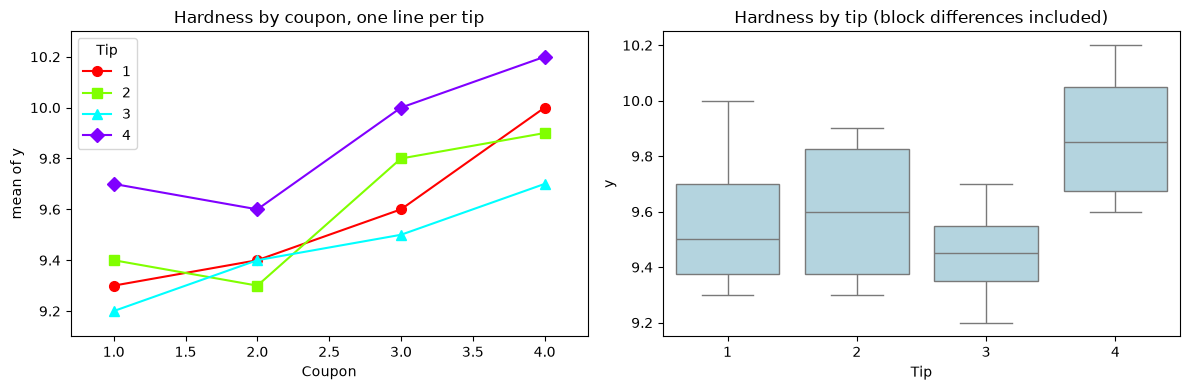

In [3]:
# Left: readings of each tip across the coupons (blocks); right: tips compared within coupons.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
interaction_plot(hard["Coupon"], hard["Tip"], hard["y"], ax=axes[0], markers=["o", "s", "^", "D"], ms=7)
axes[0].set_title("Hardness by coupon, one line per tip")
sns.boxplot(data=hard, x="Tip", y="y", ax=axes[1], color="lightblue")
axes[1].set_title("Hardness by tip (block differences included)")
plt.tight_layout(); plt.show()

The lines in the left plot are roughly parallel: the coupons shift all readings up or down by a similar amount
(block effect) and tip 4 reads highest on every coupon. The boxplot on the right mixes the coupon-to-coupon variability into
the spread of each tip, which hides the tip effect.

### ANOVA of the RCBD and the same data analysed as a completely randomized design

In [4]:
rcbd = smf.ols("y ~ C(Tip) + C(Coupon)", data=hard).fit()
crd = smf.ols("y ~ C(Tip)", data=hard).fit()
print("RCBD: tips + coupons (blocks)")
display(sm.stats.anova_lm(rcbd, typ=2))
print("CRD: blocks ignored")
display(sm.stats.anova_lm(crd, typ=2))
print(f"MS_E RCBD = {rcbd.mse_resid:.5f}, MS_E CRD = {crd.mse_resid:.5f}, ratio = {crd.mse_resid / rcbd.mse_resid:.2f}")

RCBD: tips + coupons (blocks)


,sum_sq,df,F,PR(>F)
C(Tip),0.385,3.0,14.4375,0.000871
C(Coupon),0.825,3.0,30.9375,0.000045
Residual,0.080,9.0,NaN,NaN


CRD: blocks ignored


,sum_sq,df,F,PR(>F)
C(Tip),0.385,3.0,1.701657,0.219568
Residual,0.905,12.0,NaN,NaN


MS_E RCBD = 0.00889, MS_E CRD = 0.07542, ratio = 8.48


In the RCBD the tip effect is highly significant ($F_0 = 14.44$, $p = 0.0009$). Ignoring the blocks moves $SS_{Coupon}$ into
the error term, $MS_E$ grows about 8.5 times and the tip effect is no longer detected ($p = 0.22$).

### Relative efficiency of the RCBD

How many more observations would a completely randomized design need to estimate the tip means as precisely
(Montgomery, Supplemental Material S4.1)?

$$
R = \frac{(df_b+1)(df_r+3)}{(df_b+3)(df_r+1)}\,\frac{\hat\sigma_r^2}{\hat\sigma_b^2},\qquad
\hat\sigma_r^2 = \frac{(b-1)MS_{Blocks} + b(a-1)MS_E}{ab-1},\qquad \hat\sigma_b^2 = MS_E,
$$

with $df_b = (a-1)(b-1)$ and $df_r = a(b-1)$ the error degrees of freedom of the RCBD and of the CRD.

In [5]:
def relative_efficiency(model, block, a, b):
    """Relative efficiency of an RCBD with a treatments and b blocks with respect to a CRD."""
    tab = sm.stats.anova_lm(model, typ=2)
    ms_block = tab.loc[block, "sum_sq"] / tab.loc[block, "df"]
    mse = model.mse_resid
    sigma2_crd = ((b - 1) * ms_block + b * (a - 1) * mse) / (a * b - 1)
    df_b, df_r = (a - 1) * (b - 1), a * (b - 1)
    correction = (df_b + 1) * (df_r + 3) / ((df_b + 3) * (df_r + 1))
    return sigma2_crd / mse, correction * sigma2_crd / mse

ratio, R = relative_efficiency(rcbd, "C(Coupon)", a=4, b=4)
print(f"variance ratio = {ratio:.2f}, relative efficiency R = {R:.2f}")

variance ratio = 6.99, relative efficiency R = 6.72


A completely randomized design would need about 6.7 times as many runs per tip to reach the same precision.

### Which tips differ?

Fisher's LSD and Tukey's HSD must use $MS_E$ and $df_E$ of the RCBD model. For comparison, the last output shows what
`pairwise_tukeyhsd()` reports: it fits a one-way model (blocks ignored) and finds no difference at all.

In [6]:
mse, dfe = rcbd.mse_resid, rcbd.df_resid
b = hard["Coupon"].nunique()
lsd = stats.t.ppf(0.975, dfe) * np.sqrt(2 * mse / b)
print("Tip means:", hard.groupby("Tip")["y"].mean().round(3).to_dict())
print(f"Fisher LSD = {lsd:.4f}")

tukey_tips = tukey_from_model(rcbd, hard, "Tip", "y")
tukey_tips["|diff| > LSD"] = tukey_tips["diff"].abs() > lsd
display(tukey_tips.round(4))

print("WRONG for an RCBD - pairwise_tukeyhsd() ignores the blocks:")
print(pairwise_tukeyhsd(hard["y"], hard["Tip"]))

Tip means: {1: 9.575, 2: 9.6, 3: 9.45, 4: 9.875}
Fisher LSD = 0.1508
MS_E = 0.008889, df_E = 9, n per level = 4, HSD = 0.2081


,pair,diff,lower,upper,p_adj,reject,|diff| > LSD
0,2 - 1,0.025,-0.1831,0.2331,0.9809,False,False
1,3 - 1,-0.125,-0.3331,0.0831,0.3028,False,False
2,4 - 1,0.300,0.0919,0.5081,0.0067,True,True
3,3 - 2,-0.150,-0.3581,0.0581,0.1816,False,False
4,4 - 2,0.275,0.0669,0.4831,0.0113,True,True
5,4 - 3,0.425,0.2169,0.6331,0.0006,True,True


WRONG for an RCBD - pairwise_tukeyhsd() ignores the blocks:


Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     1      2    0.025 0.9992 -0.5515 0.6015  False
     1      3   -0.125 0.9157 -0.7015 0.4515  False
     1      4      0.3 0.4431 -0.2765 0.8765  False
     2      3    -0.15 0.8653 -0.7265 0.4265  False
     2      4    0.275 0.5135 -0.3015 0.8515  False
     3      4    0.425 0.1816 -0.1515 1.0015  False
---------------------------------------------------


Tip 4 gives higher readings than tips 1, 2 and 3; tips 1, 2 and 3 do not differ (the comparison 3 - 2 is borderline for LSD).

### Model adequacy

Residuals versus fitted values, normal probability plot and residuals versus both factors. With one observation per cell
we cannot fit the tip $\times$ coupon interaction, but Tukey's one-degree-of-freedom test checks the additivity assumption.

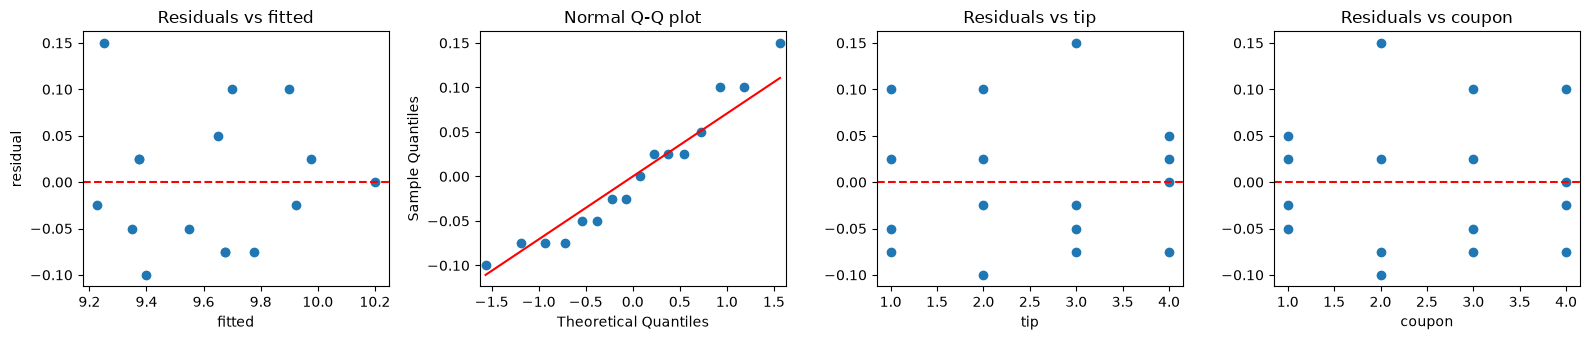

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9395749936061478), pvalue=np.float64(0.34384049244110837))

Tukey's test for nonadditivity (row q_nonadd):


,df,sum_sq,mean_sq,F,PR(>F)
C(Tip),3.0,0.38500,0.12833,13.52306,0.00169
C(Coupon),3.0,0.82500,0.27500,28.97798,0.00012
q_nonadd,1.0,0.00408,0.00408,0.42996,0.53041
Residual,8.0,0.07592,0.00949,NaN,NaN


In [7]:
res, fit = rcbd.resid, rcbd.fittedvalues
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].scatter(fit, res); axes[0].axhline(0, color="red", ls="--"); axes[0].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
sm.qqplot(res, line="s", ax=axes[1]); axes[1].set_title("Normal Q-Q plot")
axes[2].scatter(hard["Tip"], res); axes[2].axhline(0, color="red", ls="--"); axes[2].set(xlabel="tip", title="Residuals vs tip")
axes[3].scatter(hard["Coupon"], res); axes[3].axhline(0, color="red", ls="--"); axes[3].set(xlabel="coupon", title="Residuals vs coupon")
plt.tight_layout(); plt.show()

print("Shapiro-Wilk on residuals:", stats.shapiro(res))
print("\nTukey's test for nonadditivity (row q_nonadd):")
display(tukey_nonadditivity(hard, "y", "Tip", "Coupon").round(5))

No pattern in the residuals, normality is acceptable and there is no evidence of nonadditivity ($p = 0.53$).

### How many blocks?

We want to detect a true maximum difference of $D = 0.4$ between two tip means with high probability, with
$\sigma = 0.1$. For the least favourable configuration (two means $D$ apart, the others in the middle)
$\lambda = bD^2/(2\sigma^2)$, $\Phi^2 = \lambda/a$, and $F_0 \sim F_{a-1,(a-1)(b-1)}(\lambda)$ under $H_1$.

In [8]:
a, D, sigma = 4, 0.4, 0.1
rows = []
for b in range(3, 9):
    lam = b * D**2 / (2 * sigma**2)
    df1, df2 = a - 1, (a - 1) * (b - 1)
    rows.append({"blocks b": b, "Phi": np.sqrt(lam / a), "lambda": lam, "df2": df2,
                 "power": anova_power(lam, df1, df2)})
display(pd.DataFrame(rows).round(4))

,blocks b,Phi,lambda,df2,power
0,3,2.4495,24.0,6,0.8461
1,4,2.8284,32.0,9,0.9757
2,5,3.1623,40.0,12,0.9972
3,6,3.4641,48.0,15,0.9997
4,7,3.7417,56.0,18,1.0000
5,8,4.0000,64.0,21,1.0000


## 2. Lecture example: battery life (two-factor factorial)

Montgomery, Example 5.1: the effective life (hours) of a battery for three plate materials and three temperatures
(15, 70, 125 $^\circ$F), $n = 4$ replicates, all 36 runs in random order. Questions: what effects do material and
temperature have on life, and is there a material that gives uniformly long life regardless of temperature?

In [9]:
bat = pd.read_csv(URL + "battery.txt", sep=r"\s+")
print(bat.shape)
display(bat.pivot_table(index="Material", columns="Temperature", values="Life", aggfunc="mean"))
display(bat.pivot_table(index="Material", columns="Temperature", values="Life", aggfunc="std").round(2))

(36, 3)


Temperature,15,70,125
Material,,,
1,134.75,57.25,57.5
2,155.75,119.75,49.5
3,144.00,145.75,85.5


Temperature,15,70,125
Material,,,
1,45.35,23.60,26.85
2,25.62,12.66,19.26
3,25.97,22.54,19.28


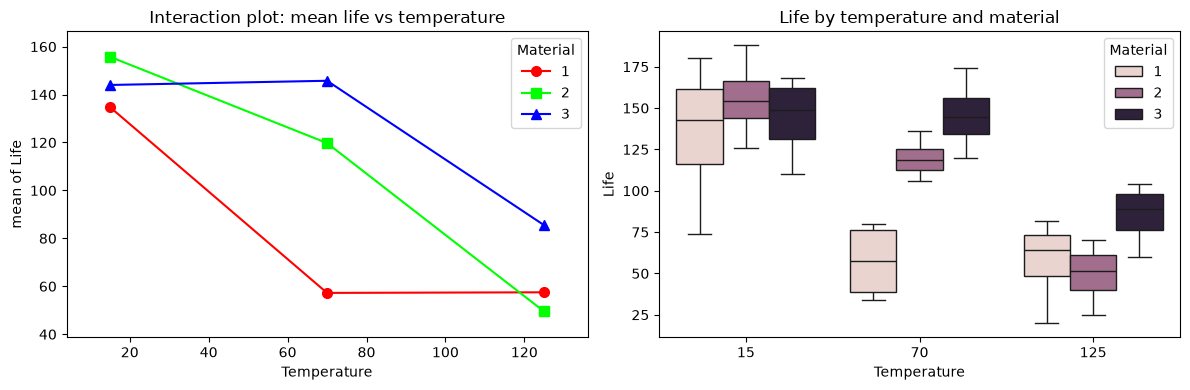

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
interaction_plot(bat["Temperature"], bat["Material"], bat["Life"], ax=axes[0], markers=["o", "s", "^"], ms=7)
axes[0].set_title("Interaction plot: mean life vs temperature")
sns.boxplot(data=bat, x="Temperature", y="Life", hue="Material", ax=axes[1])
axes[1].set_title("Life by temperature and material")
plt.tight_layout(); plt.show()

The lines are not parallel: material 1 loses most of its life already at 70 $^\circ$F, materials 2 and 3 only at 125 $^\circ$F.

### ANOVA with and without interaction

In [11]:
full = smf.ols("Life ~ C(Material) * C(Temperature)", data=bat).fit()
add = smf.ols("Life ~ C(Material) + C(Temperature)", data=bat).fit()
display(sm.stats.anova_lm(full, typ=2))
display(sm.stats.anova_lm(add, typ=2))
print("F-test for the interaction (additive vs full model):")
display(sm.stats.anova_lm(add, full))

,sum_sq,df,F,PR(>F)
C(Material),10683.722222,2.0,7.911372,1.976083e-03
C(Temperature),39118.722222,2.0,28.967692,1.908596e-07
C(Material):C(Temperature),9613.777778,4.0,3.559535,1.861117e-02
Residual,18230.750000,27.0,NaN,NaN


,sum_sq,df,F,PR(>F)
C(Material),10683.722222,2.0,5.947226,0.006515
C(Temperature),39118.722222,2.0,21.775919,0.000001
Residual,27844.527778,31.0,NaN,NaN


F-test for the interaction (additive vs full model):


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,31.0,27844.527778,0.0,NaN,NaN,NaN
1,27.0,18230.750000,4.0,9613.777778,3.559535,0.018611


### Model adequacy

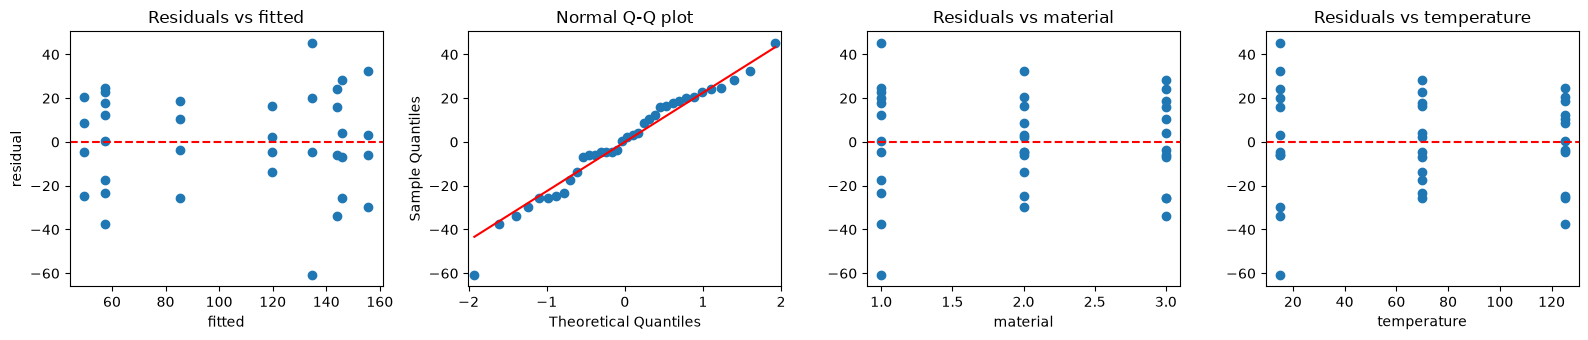

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9760570230871318), pvalue=np.float64(0.6117266783415353))
Levene (Brown-Forsythe) across the 9 cells: LeveneResult(statistic=np.float64(0.7995970449966421), pvalue=np.float64(0.6081330500874305))


In [12]:
res, fit = full.resid, full.fittedvalues
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].scatter(fit, res); axes[0].axhline(0, color="red", ls="--"); axes[0].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
sm.qqplot(res, line="s", ax=axes[1]); axes[1].set_title("Normal Q-Q plot")
axes[2].scatter(bat["Material"], res); axes[2].axhline(0, color="red", ls="--"); axes[2].set(xlabel="material", title="Residuals vs material")
axes[3].scatter(bat["Temperature"], res); axes[3].axhline(0, color="red", ls="--"); axes[3].set(xlabel="temperature", title="Residuals vs temperature")
plt.tight_layout(); plt.show()

cells_ = [g["Life"].to_numpy(dtype=float) for _, g in bat.groupby(["Material", "Temperature"])]
print("Shapiro-Wilk on residuals:", stats.shapiro(res))
print("Levene (Brown-Forsythe) across the 9 cells:", stats.levene(*cells_))

The residual plots show slightly larger spread for material 1 at 15 $^\circ$F (one low observation, 74 h), but no serious
violation of the assumptions.

### Comparisons of means

Tukey's HSD for the main effects uses $MS_E = 675.2$ with 27 df from the full model. Because the interaction is significant,
the main-effect comparisons average over very different situations; the **simple effects** (materials compared at a fixed
temperature, $n = 4$ per cell, pooled $MS_E$) answer the practical question.

In [13]:
display(tukey_from_model(full, bat, "Material", "Life").round(4))
display(tukey_from_model(full, bat, "Temperature", "Life").round(4))

MS_E = 675.2, df_E = 27, n per level = 12, HSD = 26.3


,pair,diff,lower,upper,p_adj,reject
0,2 - 1,25.1667,-1.1357,51.4690,0.0628,False
1,3 - 1,41.9167,15.6143,68.2190,0.0014,True
2,3 - 2,16.7500,-9.5523,43.0523,0.2718,False


MS_E = 675.2, df_E = 27, n per level = 12, HSD = 26.3


,pair,diff,lower,upper,p_adj,reject
0,70 - 15,-37.2500,-63.5523,-10.9477,0.0044,True
1,125 - 15,-80.6667,-106.9690,-54.3643,0.0000,True
2,125 - 70,-43.4167,-69.7190,-17.1143,0.0010,True


In [14]:
mse, dfe = full.mse_resid, full.df_resid
T = stats.studentized_range.ppf(0.95, 3, dfe) * np.sqrt(mse / 4)
print(f"Critical difference for materials within one temperature: T = {T:.2f}")
rows = []
for temp, sub in bat.groupby("Temperature"):
    m = sub.groupby("Material")["Life"].mean()
    for i, j in [(1, 2), (1, 3), (2, 3)]:
        rows.append({"Temperature": temp, "pair": f"{j} - {i}", "diff": m[j] - m[i], "significant": abs(m[j] - m[i]) > T})
pd.DataFrame(rows).pivot(index="Temperature", columns="pair", values="diff")

Critical difference for materials within one temperature: T = 45.56


pair,2 - 1,3 - 1,3 - 2
Temperature,,,
15,21.0,9.25,-11.75
70,62.5,88.50,26.00
125,-8.0,28.00,36.00


The materials differ only at 70 $^\circ$F (materials 2 and 3 better than 1). Material 3 gives long life at all three temperatures,
so it is the most robust choice.

### Sample size

How many replicates are needed to detect a difference of $D = 40$ h between two material means with $\sigma = 25$ h?
For factor $A$: $\Phi^2 = nbD^2/(2a\sigma^2)$, $\lambda = a\Phi^2$, $\nu_1 = a-1$, $\nu_2 = ab(n-1)$.

In [15]:
a = b = 3
D, sigma = 40, 25
rows = []
for n in [2, 3, 4, 5]:
    lam = n * b * D**2 / (2 * sigma**2)
    rows.append({"n": n, "Phi": np.sqrt(lam / a), "lambda": lam, "df2": a * b * (n - 1),
                 "power": anova_power(lam, a - 1, a * b * (n - 1))})
display(pd.DataFrame(rows).round(3))

,n,Phi,lambda,df2,power
0,2,1.600,7.68,9,0.542
1,3,1.960,11.52,18,0.803
2,4,2.263,15.36,27,0.923
3,5,2.530,19.20,36,0.972


### Response curves

Temperature is quantitative. With three levels we can fit at most a quadratic in temperature; letting the linear and
quadratic terms interact with material decomposes $SS_{Temperature}$ and $SS_{Material:Temperature}$ into single-degree-of-freedom parts.

,df,sum_sq,mean_sq,F,PR(>F)
C(Material),2.0,10683.722222,5341.861111,7.911372,1.976083e-03
T,1.0,39042.666667,39042.666667,57.822745,3.525248e-08
C(Material):T,2.0,2315.083333,1157.541667,1.714336,1.991088e-01
I(T ** 2),1.0,76.055556,76.055556,0.112639,7.397530e-01
C(Material):I(T ** 2),2.0,7298.694444,3649.347222,5.404735,1.061214e-02
Residual,27.0,18230.750000,675.212963,NaN,NaN


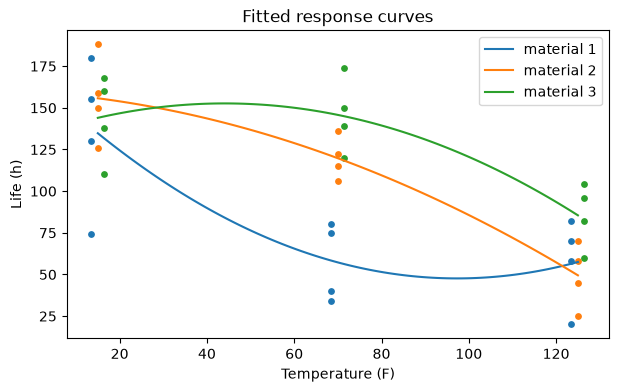

In [16]:
bat["T"] = bat["Temperature"].astype(float)
rc = smf.ols("Life ~ C(Material) + T + I(T**2) + C(Material):T + C(Material):I(T**2)", data=bat).fit()
display(sm.stats.anova_lm(rc, typ=1))

grid = np.linspace(15, 125, 100)
fig, ax = plt.subplots(figsize=(7, 4))
for mat, colour in zip([1, 2, 3], ["C0", "C1", "C2"]):
    pred = rc.predict(pd.DataFrame({"Material": mat, "T": grid}))
    ax.plot(grid, pred, color=colour, label=f"material {mat}")
    sub = bat[bat["Material"] == mat]
    ax.scatter(sub["T"] + (mat - 2) * 1.5, sub["Life"], color=colour, s=15)
ax.set(xlabel="Temperature (F)", ylabel="Life (h)", title="Fitted response curves")
ax.legend(); plt.show()

## 3. Lecture examples: blocking in a factorial, three factors, response surface

### Radar target detection (Example 5.6): a factorial run in blocks

Factors: filter type (2) and ground clutter (low, medium, high). Each of four operators runs all six combinations in
random order, so the operator is a **block**. The model is $y_{ijk} = \mu + \tau_i + \beta_j + (\tau\beta)_{ij} + \delta_k + \varepsilon_{ijk}$.

With operators as blocks


,sum_sq,df,F,PR(>F)
C(Operator),402.166667,3.0,12.089178,2.771485e-04
C(Filter),1066.666667,1.0,96.192385,6.446793e-08
C(Ground),335.583333,2.0,15.131513,2.527013e-04
C(Filter):C(Ground),77.083333,2.0,3.475701,5.750655e-02
Residual,166.333333,15.0,NaN,NaN


Blocks ignored


,sum_sq,df,F,PR(>F)
C(Filter),1066.666667,1.0,33.773087,0.000017
C(Ground),335.583333,2.0,5.312665,0.015371
C(Filter):C(Ground),77.083333,2.0,1.220317,0.318422
Residual,568.500000,18.0,NaN,NaN


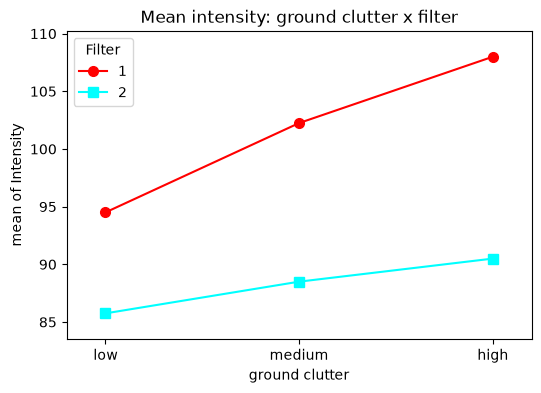

In [17]:
radar = pd.read_csv(URL + "intensity.txt", sep=r"\s+")
radar["Ground"] = pd.Categorical(radar["Ground"], categories=["low", "medium", "high"], ordered=True)
blk = smf.ols("Intensity ~ C(Operator) + C(Filter) * C(Ground)", data=radar).fit()
noblk = smf.ols("Intensity ~ C(Filter) * C(Ground)", data=radar).fit()
print("With operators as blocks"); display(sm.stats.anova_lm(blk, typ=2))
print("Blocks ignored"); display(sm.stats.anova_lm(noblk, typ=2))

fig, ax = plt.subplots(figsize=(6, 4))
interaction_plot(radar["Ground"].cat.codes, radar["Filter"], radar["Intensity"], ax=ax, markers=["o", "s"], ms=7)
ax.set_xticks([0, 1, 2], radar["Ground"].cat.categories)
ax.set(xlabel="ground clutter", title="Mean intensity: ground clutter x filter"); plt.show()

### Soft drink bottling (Example 5.3): three factors

Deviation from the target fill height for carbonation (10, 12, 14 %), operating pressure (25, 30 psi) and line speed
(200, 250 bottles/min), two replicates.

,sum_sq,df,F,PR(>F)
C(Carbonation),252.750000,2.0,178.411765,1.186249e-09
C(Pressure),45.375000,1.0,64.058824,3.742257e-06
C(Speed),22.041667,1.0,31.117647,1.202174e-04
C(Carbonation):C(Pressure),5.250000,2.0,3.705882,5.580812e-02
C(Carbonation):C(Speed),0.583333,2.0,0.411765,6.714939e-01
C(Pressure):C(Speed),1.041667,1.0,1.470588,2.485867e-01
C(Carbonation):C(Pressure):C(Speed),1.083333,2.0,0.764706,4.868711e-01
Residual,8.500000,12.0,NaN,NaN


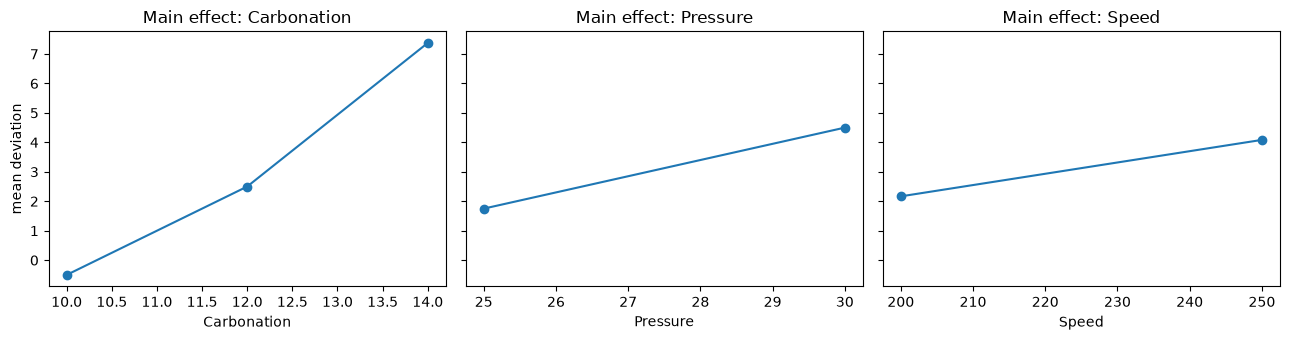

In [18]:
bot = pd.read_csv(URL + "bottling.txt", sep=r"\s+")
m3 = smf.ols("Deviation ~ C(Carbonation) * C(Pressure) * C(Speed)", data=bot).fit()
display(sm.stats.anova_lm(m3, typ=2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, factor in zip(axes, ["Carbonation", "Pressure", "Speed"]):
    bot.groupby(factor)["Deviation"].mean().plot(marker="o", ax=ax)
    ax.set_title(f"Main effect: {factor}"); ax.set_ylabel("mean deviation")
plt.tight_layout(); plt.show()

### Tool life (Example 5.5): response surface for two quantitative factors

Cutting angle (15, 20, 25 degrees) and cutting speed (125, 150, 175 in/min), two replicates. The full model with linear and
quadratic terms in both factors and all their products has 9 parameters, one per cell mean.

,df,sum_sq,mean_sq,F,PR(>F)
Angle,1.0,8.333333,8.333333,5.769231,0.039772
I(Angle ** 2),1.0,16.000000,16.000000,11.076923,0.008824
Speed,1.0,21.333333,21.333333,14.769231,0.003948
I(Speed ** 2),1.0,4.000000,4.000000,2.769231,0.130451
Angle:Speed,1.0,8.000000,8.000000,5.538462,0.043065
Angle:I(Speed ** 2),1.0,42.666667,42.666667,29.538462,0.000414
I(Angle ** 2):Speed,1.0,2.666667,2.666667,1.846154,0.207306
I(Angle ** 2):I(Speed ** 2),1.0,8.000000,8.000000,5.538462,0.043065
Residual,9.0,13.000000,1.444444,NaN,NaN


Intercept                     -1068.000000
Angle                           136.300000
I(Angle ** 2)                    -4.080000
Speed                            14.480000
I(Speed ** 2)                    -0.049600
Angle:Speed                      -1.864000
Angle:I(Speed ** 2)               0.006400
I(Angle ** 2):Speed               0.056000
I(Angle ** 2):I(Speed ** 2)      -0.000192
dtype: float64


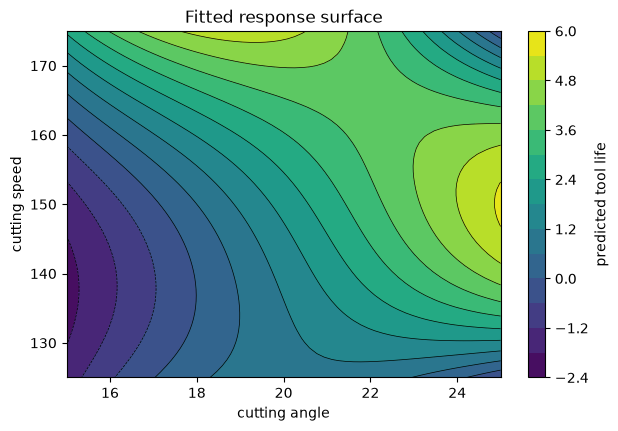

In [19]:
tool = pd.read_csv(URL + "toollife.txt", sep=r"\s+")
rs = smf.ols("Life ~ (Angle + I(Angle**2)) * (Speed + I(Speed**2))", data=tool).fit()
display(sm.stats.anova_lm(rs, typ=1))
print(rs.params.round(6))

A, S = np.meshgrid(np.linspace(15, 25, 60), np.linspace(125, 175, 60))
Z = rs.predict(pd.DataFrame({"Angle": A.ravel(), "Speed": S.ravel()})).to_numpy().reshape(A.shape)
fig, ax = plt.subplots(figsize=(7, 4.5))
cs = ax.contourf(A, S, Z, levels=12, cmap="viridis")
ax.contour(A, S, Z, levels=12, colors="k", linewidths=0.5)
fig.colorbar(cs, label="predicted tool life")
ax.set(xlabel="cutting angle", ylabel="cutting speed", title="Fitted response surface")
plt.show()

## In-class problems

Work in pairs; we discuss the results at the end of the class. For every test state the hypotheses, the test statistic,
the $p$-value and your decision.

### Problem 4.3 (with 4.16): chemical agents and cloth strength

A chemist wishes to test the effect of four chemical agents on the strength of a particular type of cloth. Because there might
be variability from one bolt to another, the chemist decides to use a randomized block design, with the bolts of cloth
considered as blocks. She selects five bolts and applies all four chemicals in random order to each bolt.
The resulting tensile strengths are:

| Chemical | Bolt 1 | Bolt 2 | Bolt 3 | Bolt 4 | Bolt 5 |
|---|---|---|---|---|---|
| 1 | 73 | 68 | 74 | 71 | 67 |
| 2 | 73 | 67 | 75 | 72 | 70 |
| 3 | 75 | 68 | 78 | 73 | 68 |
| 4 | 73 | 71 | 75 | 75 | 69 |

In [20]:
strength = [[73, 68, 74, 71, 67],
            [73, 67, 75, 72, 70],
            [75, 68, 78, 73, 68],
            [73, 71, 75, 75, 69]]
cloth = pd.DataFrame([(c + 1, b + 1, strength[c][b]) for c in range(4) for b in range(5)],
                     columns=["Chemical", "Bolt", "Strength"])
cloth.pivot(index="Chemical", columns="Bolt", values="Strength")

Bolt,1,2,3,4,5
Chemical,,,,,
1,73,68,74,71,67
2,73,67,75,72,70
3,75,68,78,73,68
4,73,71,75,75,69


**Question 1.** Plot the data (strength versus bolt, one line per chemical). What do you expect from the analysis?

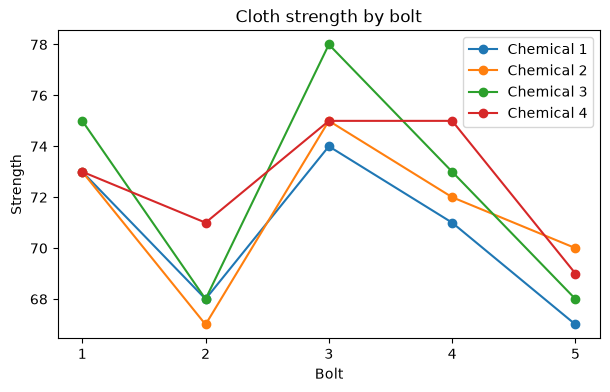

In [21]:
# Helpers for the solutions below. All decisions use alpha = 0.05.
def report_anova(model):
    table = sm.stats.anova_lm(model, typ=2)
    display(table)
    for term, row in table.drop(index='Residual').iterrows():
        print(f"{term}: F({row['df']:.0f}, {model.df_resid:.0f}) = {row['F']:.4f}, "
              f"p = {row['PR(>F)']:.6g}; "
              + ('reject H0' if row['PR(>F)'] < 0.05 else 'do not reject H0'))
    print(f'Pooled error MS = {model.mse_resid:.6g}')
    return table


def residual_checks(model, data, factors, title):
    # Run order is not supplied: row index is not a valid time sequence.
    fig, axes = plt.subplots(1, 2 + len(factors), figsize=(4 * (2 + len(factors)), 3.6))
    axes[0].scatter(model.fittedvalues, model.resid)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set(xlabel='Fitted', ylabel='Residual', title='Residuals vs fitted')
    stats.probplot(model.resid, plot=axes[1])
    axes[1].set_title('Normal Q-Q plot')
    for ax, factor in zip(axes[2:], factors):
        for pos, level in enumerate(sorted(data[factor].unique())):
            values = model.resid[data[factor] == level]
            ax.scatter(np.full(len(values), pos), values, alpha=0.7)
        ax.set_xticks(range(data[factor].nunique()), sorted(data[factor].unique()))
        ax.axhline(0, color='red', linestyle='--')
        ax.set(xlabel=factor, ylabel='Residual')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    # H0: normal errors; H1: non-normality. Residual-based p-values are diagnostic:
    # fitted residuals are correlated, especially with only two observations/cell.
    sw = stats.shapiro(model.resid)
    print(f'Shapiro-Wilk: W = {sw.statistic:.4f}, p = {sw.pvalue:.5f}; '
          + ('reject normality at 0.05 (diagnostic)' if sw.pvalue < 0.05
             else 'do not reject normality (diagnostic)'))


def nonadditivity_report(data, response, row, col):
    # H0: multiplicative nonadditivity coefficient = 0; H1: it is nonzero.
    table = tukey_nonadditivity(data, response, row, col)
    display(table)
    test = table.loc['q_nonadd']
    print(f"Nonadditivity: F(1, {table.loc['Residual', 'df']:.0f}) = {test['F']:.4f}, "
          f"p = {test['PR(>F)']:.5f}; "
          + ('reject H0' if test['PR(>F)'] < 0.05 else 'do not reject H0'))


def blocking_efficiency(model, data, response, treatment, block):
    a, b = data[treatment].nunique(), data[block].nunique()
    table = sm.stats.anova_lm(model, typ=2)
    ms_block = table.loc[f'C({block})', 'sum_sq'] / (b - 1)
    crd = smf.ols(f'{response} ~ C({treatment})', data=data).fit()
    print('CRD: H0 = equal treatment means; H1 = at least one differs.')
    report_anova(crd)
    # Lecture's df-corrected RCBD/CRD relative efficiency, not just MSE_CRD/MSE_RCBD.
    var_crd = ((b - 1) * ms_block + b * (a - 1) * model.mse_resid) / (a*b - 1)
    df_b, df_r = model.df_resid, crd.df_resid
    correction = (df_b + 1)*(df_r + 3)/((df_b + 3)*(df_r + 1))
    R = correction * var_crd / model.mse_resid
    print(f'MSE RCBD = {model.mse_resid:.5f}, MSE CRD = {crd.mse_resid:.5f}')
    print(f'Estimated CRD variance = {var_crd:.5f}; relative efficiency R = {R:.4f}')
    return crd


def block_variance(model, cells_per_block):
    table = sm.stats.anova_lm(model, typ=2)
    ms_block = table.loc['C(Block)', 'sum_sq'] / table.loc['C(Block)', 'df']
    estimate = (ms_block - model.mse_resid) / cells_per_block
    print(f'MS Block = {ms_block:.5f}; raw block variance estimate = {estimate:.5f}')
    print(f'Nonnegative variance estimate = {max(0, estimate):.5f}')
    return estimate

fig, ax = plt.subplots(figsize=(7, 4))
for chemical, group in cloth.groupby('Chemical'):
    ax.plot(group['Bolt'], group['Strength'], marker='o', label=f'Chemical {chemical}')
ax.set(xlabel='Bolt', ylabel='Strength', xticks=range(1, 6), title='Cloth strength by bolt')
ax.legend()
plt.show()

The chemicals follow a similar bolt-to-bolt pattern: bolts 1 and 3 tend to be stronger, while 2 and 5 are weaker. I expect a substantial bolt effect and a smaller chemical effect; blocking should improve precision.

**Question 2.** Analyse the data as an RCBD with $\alpha = 0.05$. Do the chemicals differ?

In [22]:
# H0 for chemicals: all four chemical mean effects are equal (tau_i = 0).
# H0 for bolts: all five bolt effects are zero. Each H1: some effect is nonzero.
cloth_model = smf.ols('Strength ~ C(Chemical) + C(Bolt)', data=cloth).fit()
cloth_anova = report_anova(cloth_model)

,sum_sq,df,F,PR(>F)
C(Chemical),12.95,3.0,2.376147,0.121144
C(Bolt),157.00,4.0,21.605505,0.000021
Residual,21.80,12.0,NaN,NaN


C(Chemical): F(3, 12) = 2.3761, p = 0.121144; do not reject H0
C(Bolt): F(4, 12) = 21.6055, p = 2.05918e-05; reject H0
Pooled error MS = 1.81667


Chemical differences are not established: $F(3,12)=2.376$, $p=0.1211$. Bolts differ strongly, $F(4,12)=21.606$, $p=0.000021$. This is an additive RCBD analysis; with one observation per cell, general chemical-by-bolt interaction cannot be separately estimated.

**Question 3.** (Problem 4.16) Assuming that chemical types and bolts are fixed, estimate the model parameters $\tau_i$ and $\beta_j$.

In [23]:
# Sum-to-zero constraints identify the fixed treatment and block effects.
cloth_grand = cloth['Strength'].mean()
print(f'Grand mean = {cloth_grand:.3f}')
display((cloth.groupby('Chemical')['Strength'].mean() - cloth_grand).rename('tau'))
display((cloth.groupby('Bolt')['Strength'].mean() - cloth_grand).rename('beta'))

Grand mean = 71.750


Chemical
1   -1.15
2   -0.35
3    0.65
4    0.85
Name: tau, dtype: float64

Bolt
1    1.75
2   -3.25
3    3.75
4    1.00
5   -3.25
Name: beta, dtype: float64

The estimates are $\hat\mu=71.75$, $\hat\tau=(-1.15,-0.35,0.65,0.85)$ and $\hat\beta=(1.75,-3.25,3.75,1.00,-3.25)$. Each set of effects sums to zero; these are deviations from the grand mean rather than reference-level regression coefficients.

**Question 4.** Analyse the same data as if they came from a completely randomized design. Compare the error mean squares and compute the relative efficiency of the RCBD. Was blocking worthwhile?

In [24]:
cloth_crd = blocking_efficiency(cloth_model, cloth, 'Strength', 'Chemical', 'Bolt')

CRD: H0 = equal treatment means; H1 = at least one differs.


,sum_sq,df,F,PR(>F)
C(Chemical),12.95,3.0,0.386279,0.764377
Residual,178.80,16.0,NaN,NaN


C(Chemical): F(3, 16) = 0.3863, p = 0.764377; do not reject H0
Pooled error MS = 11.175
MSE RCBD = 1.81667, MSE CRD = 11.17500
Estimated CRD variance = 9.69737; relative efficiency R = 5.1705


Ignoring bolts gives $MS_E=11.175$ instead of 1.817, and $F(3,16)=0.386$, $p=0.7644$ for chemicals. The lecture’s corrected relative efficiency is $R=5.171$, so a comparable CRD would need roughly 5.2 times as many observations per treatment to attain similar precision. Blocking was worthwhile even though chemical differences remain nonsignificant.

**Question 5.** Analyse the residuals and perform Tukey's test for nonadditivity. Comment on model adequacy.

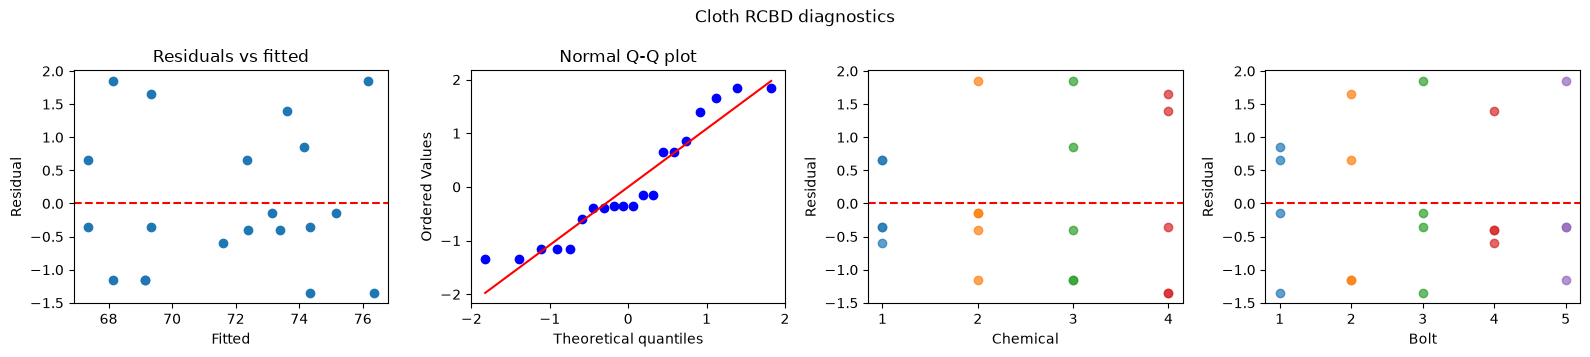

Shapiro-Wilk: W = 0.8996, p = 0.04054; reject normality at 0.05 (diagnostic)


,df,sum_sq,mean_sq,F,PR(>F)
C(Chemical),3.0,12.95000,4.316667,2.199132,0.145637
C(Bolt),4.0,157.00000,39.250000,19.995971,0.000052
q_nonadd,1.0,0.20815,0.208150,0.106042,0.750806
Residual,11.0,21.59185,1.962895,NaN,NaN


Nonadditivity: F(1, 11) = 0.1060, p = 0.75081; do not reject H0


In [25]:
residual_checks(cloth_model, cloth, ['Chemical', 'Bolt'], 'Cloth RCBD diagnostics')
nonadditivity_report(cloth, 'Strength', 'Chemical', 'Bolt')

Shapiro–Wilk gives $W=0.900$, $p=0.0405$, flagging a possible normality departure. The Q-Q plot has a central cluster and visible departures from the line, while chemical 1 has less residual spread than the other chemicals. Tukey’s nonadditivity test gives $F(1,11)=0.106$, $p=0.7508$: no evidence of this particular multiplicative interaction. This test cannot rule out other interactions. With a small sample and a normality concern, the chemical-effect conclusion should be treated cautiously; the large bolt effect still supports blocking. Randomization within bolts supports independence.

### Problems 5.4, 5.5 and 5.34: surface finish of a metal part

An engineer suspects that the surface finish of a metal part is influenced by the feed rate and the depth of cut. He selects
three feed rates (0.20, 0.25, 0.30 in/min) and four depths of cut (0.15, 0.18, 0.20, 0.25 in), and runs a factorial experiment
with three replicates.

In [26]:
finish = pd.read_csv(URL + "Chapter5_Pr02.csv", sep=";")
finish.columns = ["Depth", "Feed", "Finish"]
display(finish.pivot_table(index="Feed", columns="Depth", values="Finish", aggfunc=list))

Depth,0.15,0.18,0.20,0.25
Feed,,,,
0.20,"[74, 64, 60]","[79, 68, 73]","[82, 88, 92]","[99, 104, 96]"
0.25,"[92, 86, 88]","[98, 104, 88]","[99, 108, 95]","[104, 110, 99]"
0.30,"[99, 98, 102]","[104, 99, 95]","[108, 110, 99]","[114, 107, 111]"


**Question 1.** Draw an interaction plot. Then analyse the data and draw conclusions; report the $p$-values ($\alpha = 0.05$).

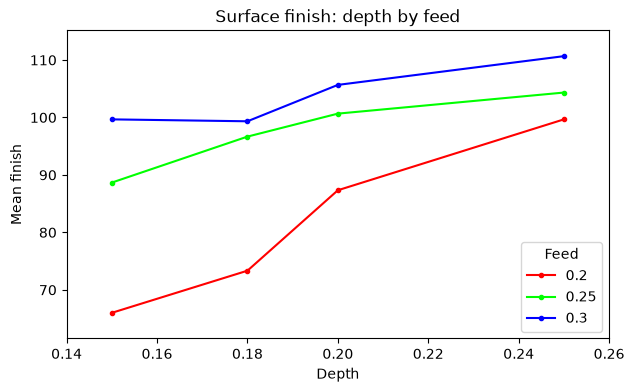

,sum_sq,df,F,PR(>F)
C(Feed),3160.500000,2.0,55.018375,1.086046e-09
C(Depth),2125.111111,3.0,24.662798,1.652000e-07
C(Feed):C(Depth),557.055556,6.0,3.232431,1.797302e-02
Residual,689.333333,24.0,NaN,NaN


C(Feed): F(2, 24) = 55.0184, p = 1.08605e-09; reject H0
C(Depth): F(3, 24) = 24.6628, p = 1.652e-07; reject H0
C(Feed):C(Depth): F(6, 24) = 3.2324, p = 0.017973; reject H0
Pooled error MS = 28.7222


In [27]:
fig, ax = plt.subplots(figsize=(7, 4))
interaction_plot(finish['Depth'], finish['Feed'], finish['Finish'], ax=ax)
ax.set(title='Surface finish: depth by feed', xlabel='Depth', ylabel='Mean finish')
plt.show()
# Main-effect H0: marginal means are equal. Interaction H0: all interaction effects
# are zero. The alternative for each test is that at least one relevant effect differs.
finish_model = smf.ols('Finish ~ C(Feed)*C(Depth)', data=finish).fit()
finish_anova = report_anova(finish_model)

Feed, depth and their interaction are significant: $F=55.018$ ($p=1.09\times10^{-9}$), $24.663$ ($p=1.65\times10^{-7}$), and $3.232$ ($p=0.0180$), respectively. The nonparallel lines show that the depth effect depends on feed. Main effects describe averages over the other factor and should not be interpreted as constant effects at every setting.

**Question 2.** Prepare appropriate residual plots and comment on the model's adequacy.

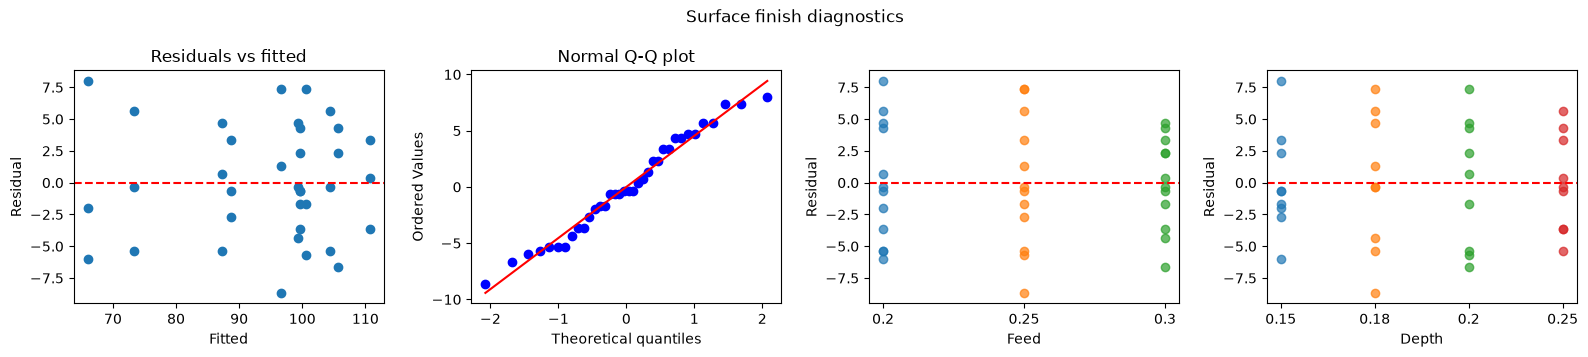

Shapiro-Wilk: W = 0.9705, p = 0.43967; do not reject normality (diagnostic)


In [28]:
residual_checks(finish_model, finish, ['Feed', 'Depth'], 'Surface finish diagnostics')

The normal Q-Q plot and Shapiro–Wilk result ($W=0.971$, $p=0.440$) do not indicate a strong normality problem. Residuals are centered around zero without a clear funnel; depth 0.25 has somewhat less spread. With three replicates per cell, variance diagnostics are imprecise. Independence relies on randomized runs, since chronological run order is not supplied. The full interaction model provides a reasonable working analysis.

**Question 3.** Obtain point estimates of the mean surface finish at each feed rate.

In [29]:
display(finish.groupby('Feed')['Finish'].mean().rename('Estimated marginal mean'))

Feed
0.20     81.583333
0.25     97.583333
0.30    103.833333
Name: Estimated marginal mean, dtype: float64

Estimated mean finish at feeds 0.20, 0.25 and 0.30 in/min is 81.583, 97.583 and 103.833. Each averages equally over the four tested depths; because of interaction, these averages do not describe every depth individually.

**Question 4.** (Problem 5.5) Compute a 95 percent confidence interval for the mean difference in response for feed rates of 0.20 and 0.25 in/min.

In [30]:
feed_means = finish.groupby('Feed')['Finish'].mean()
difference = feed_means.loc[0.20] - feed_means.loc[0.25]
n_per_feed = finish.groupby('Feed').size()
se = np.sqrt(finish_model.mse_resid * (1/n_per_feed.loc[0.20] + 1/n_per_feed.loc[0.25]))
ci = difference + np.array([-1, 1]) * stats.t.ppf(0.975, finish_model.df_resid) * se
print(f'Feed 0.20 - 0.25: estimate = {difference:.3f}; SE = {se:.3f}')
print(f'Individual 95% CI = ({ci[0]:.3f}, {ci[1]:.3f}), df = {finish_model.df_resid:.0f}')

Feed 0.20 - 0.25: estimate = -16.000; SE = 2.188
Individual 95% CI = (-20.516, -11.484), df = 24


The difference is −16.000, with an individual 95% interval of approximately (−20.516, −11.484). The mean response at feed 0.20 is lower when averaged over the four depths. The interval uses the full factorial model’s pure-error mean square, with 12 observations per feed and 24 error degrees of freedom.

**Question 5.** (Problem 5.34) Suppose that the experiment had been conducted in three blocks, with each replicate a block.
The observations in the data table are given in order: the first observation in each cell comes from the first replicate, and so on.
Reanalyse the data as a factorial experiment in blocks and estimate the variance component for blocks,
$\hat\sigma^2_{Block} = (MS_{Blocks} - MS_E)/(ab)$. Does blocking appear to be useful?

In [31]:
finish['Block'] = finish.groupby(['Feed', 'Depth']).cumcount() + 1
# Same factorial hypotheses; additionally H0: no block effect.
finish_blocked = smf.ols('Finish ~ C(Feed)*C(Depth) + C(Block)', data=finish).fit()
finish_blocked_anova = report_anova(finish_blocked)
finish_block_variance = block_variance(finish_blocked, cells_per_block=12)

,sum_sq,df,F,PR(>F)
C(Feed),3160.500000,2.0,63.985583,6.769616e-10
C(Depth),2125.111111,3.0,28.682481,8.700277e-08
C(Block),146.000000,2.0,2.955828,7.294706e-02
C(Feed):C(Depth),557.055556,6.0,3.759271,9.987786e-03
Residual,543.333333,22.0,NaN,NaN


C(Feed): F(2, 22) = 63.9856, p = 6.76962e-10; reject H0
C(Depth): F(3, 22) = 28.6825, p = 8.70028e-08; reject H0
C(Block): F(2, 22) = 2.9558, p = 0.0729471; do not reject H0
C(Feed):C(Depth): F(6, 22) = 3.7593, p = 0.00998779; reject H0
Pooled error MS = 24.697
MS Block = 73.00000; raw block variance estimate = 4.02525
Nonnegative variance estimate = 4.02525


Blocking lowers $MS_E$ from 28.722 to 24.697. The block test gives $F(2,22)=2.956$, $p=0.0729$, so a block effect is not established at 5%. The estimated random-block variance is 4.025; this suggests a modest possible benefit, but evidence is limited. Feed, depth and their interaction remain significant. This reanalysis assumes additive blocks with no block-by-treatment interaction.

**Question 6.** Depth of cut is quantitative. Fit a model with linear and quadratic terms in depth (interacting with feed rate as a factor). Is a curvature in depth needed?

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,30.0,842.100629,0.0,NaN,NaN,NaN
1,27.0,788.301898,3.0,53.798731,0.614217,0.611714


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,27.0,788.301898,0.0,NaN,NaN,NaN
1,24.0,689.333333,3.0,98.968565,1.148571,0.349745


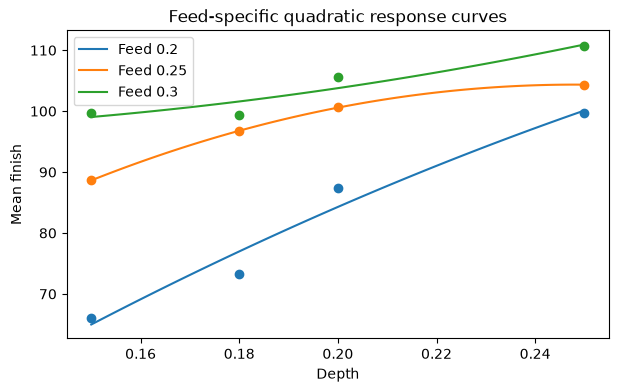

In [32]:
finish_linear = smf.ols('Finish ~ C(Feed)*Depth', data=finish).fit()
finish_quadratic = smf.ols('Finish ~ C(Feed)*(Depth + I(Depth**2))', data=finish).fit()
# H0: all three feed-specific quadratic coefficients are zero; H1: some are nonzero.
curvature_test = sm.stats.anova_lm(finish_linear, finish_quadratic)
display(curvature_test)
# H0: feed-specific quadratic curves describe all cell means; H1: lack of fit.
lackfit_test = sm.stats.anova_lm(finish_quadratic, finish_model)
display(lackfit_test)
fig, ax = plt.subplots(figsize=(7, 4))
for feed, group in finish.groupby('Feed'):
    depth = np.linspace(group['Depth'].min(), group['Depth'].max(), 100)
    predicted = finish_quadratic.predict(pd.DataFrame({'Feed': feed, 'Depth': depth}))
    line, = ax.plot(depth, predicted, label=f'Feed {feed}')
    means = group.groupby('Depth')['Finish'].mean()
    ax.scatter(means.index, means, color=line.get_color())
ax.set(xlabel='Depth', ylabel='Mean finish', title='Feed-specific quadratic response curves')
ax.legend()
plt.show()

Adding the three quadratic terms gives $F(3,27)=0.614$, $p=0.6117$, so curvature is not needed on this evidence; do not reject the linear-curve model. The quadratic model also has no significant lack of fit relative to unrestricted cell means: $F(3,24)=1.149$, $p=0.3497$. Different feed-specific slopes remain appropriate; absence of detected curvature does not remove the feed-by-depth interaction.

### Problem 5.15: two factors, one observation per cell

Analyse the following data from a two-factor factorial experiment and draw conclusions. Perform a test for nonadditivity
($\alpha = 0.05$).

| Row factor | Column 1 | Column 2 | Column 3 | Column 4 |
|---|---|---|---|---|
| 1 | 36 | 39 | 36 | 32 |
| 2 | 18 | 20 | 22 | 20 |
| 3 | 30 | 37 | 33 | 34 |

In [33]:
p515 = pd.read_csv(URL + "Chapter5_Pr13.csv", sep=";")
p515.pivot(index="Row", columns="Column", values="Data")

Column,1,2,3,4
Row,,,,
1,36,39,36,32
2,18,20,22,20
3,30,37,33,34


**Question 1.** Fit the additive model and test the main effects.

In [34]:
# H0 for each factor: its marginal means are equal; H1: some differ.
p515_model = smf.ols('Data ~ C(Row) + C(Column)', data=p515).fit()
p515_anova = report_anova(p515_model)

,sum_sq,df,F,PR(>F)
C(Row),580.500000,2.0,60.398844,0.000106
C(Column),28.916667,3.0,2.005780,0.214717
Residual,28.833333,6.0,NaN,NaN


C(Row): F(2, 6) = 60.3988, p = 0.000105955; reject H0
C(Column): F(3, 6) = 2.0058, p = 0.214717; do not reject H0
Pooled error MS = 4.80556


Rows differ: $F(2,6)=60.399$, $p=0.000106$. Columns are not significant: $F(3,6)=2.006$, $p=0.2147$. These tests assume additivity; without replication, arbitrary interaction cannot be separated from error.

**Question 2.** Perform Tukey's test for nonadditivity. What does the result mean for the conclusions of Question 1?

,df,sum_sq,mean_sq,F,PR(>F)
C(Row),2.0,580.500000,290.250000,57.377969,0.000356
C(Column),3.0,28.916667,9.638889,1.905460,0.246689
q_nonadd,1.0,3.540525,3.540525,0.699907,0.440953
Residual,5.0,25.292809,5.058562,NaN,NaN


Nonadditivity: F(1, 5) = 0.6999, p = 0.44095; do not reject H0


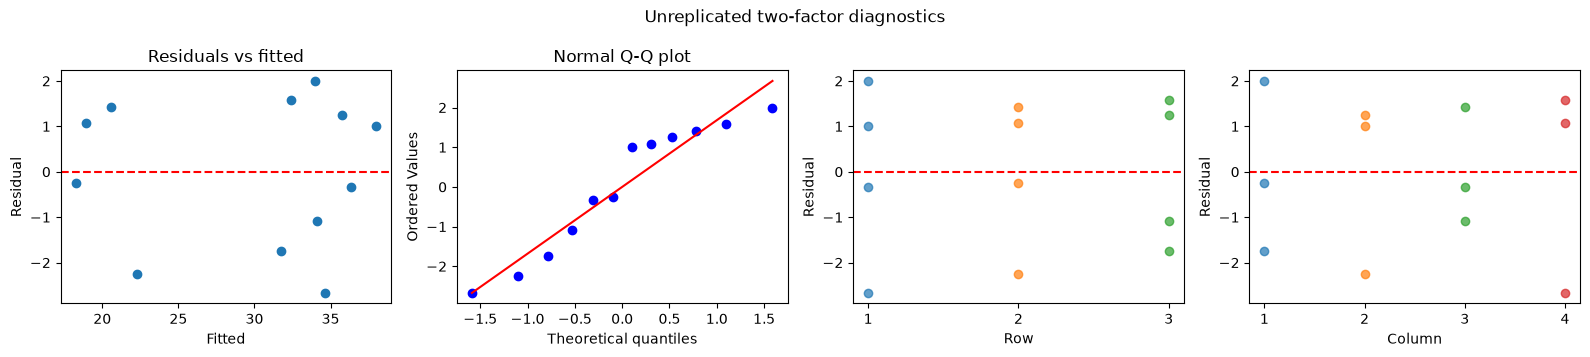

Shapiro-Wilk: W = 0.9063, p = 0.19108; do not reject normality (diagnostic)


In [35]:
nonadditivity_report(p515, 'Data', 'Row', 'Column')
residual_checks(p515_model, p515, ['Row', 'Column'], 'Unreplicated two-factor diagnostics')

Tukey’s test gives $F(1,5)=0.700$, $p=0.4410$, so multiplicative nonadditivity is not detected. Shapiro–Wilk gives $p=0.191$. The additive-model row conclusion remains reasonable, conditional on the assumptions, while no column effect is established. The small unreplicated experiment cannot verify general absence of interaction or establish equal variances reliably.

## Assignment

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **4.21, 5.8 with 5.23, 5.18 and 5.20**.
  Start in class and finish at home.
* For every test state the hypotheses, report the test statistic, its $p$-value and your decision; for comparisons of means
  say which procedure and which error mean square you use; check the assumptions with residual plots; end each problem with
  a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex03_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 18 October 2026** (the next lecture is on 19 October).

### Problem 4.21: eye focus time

An industrial engineer is conducting an experiment on eye focus time. He is interested in the effect of the distance of the
object from the eye on the focus time. Four different distances are of interest. He has five subjects available for the
experiment. Because there may be differences among individuals, he decides to conduct the experiment in a randomized block design.

| Distance (ft) | Subject 1 | Subject 2 | Subject 3 | Subject 4 | Subject 5 |
|---|---|---|---|---|---|
| 4 | 10 | 6 | 6 | 6 | 6 |
| 6 | 7 | 6 | 6 | 1 | 6 |
| 8 | 5 | 3 | 3 | 2 | 5 |
| 10 | 6 | 4 | 4 | 2 | 3 |

In [36]:
focus_time = [[10, 6, 6, 6, 6],
              [7, 6, 6, 1, 6],
              [5, 3, 3, 2, 5],
              [6, 4, 4, 2, 3]]
distances = [4, 6, 8, 10]
focus = pd.DataFrame([(distances[d], s + 1, focus_time[d][s]) for d in range(4) for s in range(5)],
                     columns=["Distance", "Subject", "Time"])
focus.pivot(index="Distance", columns="Subject", values="Time")

Subject,1,2,3,4,5
Distance,,,,,
4,10,6,6,6,6
6,7,6,6,1,6
8,5,3,3,2,5
10,6,4,4,2,3


**Question 1.** Analyse the data ($\alpha = 0.05$) and draw appropriate conclusions.

In [37]:
# H0 distance: all four distance means are equal; H1: at least one differs.
# H0 subject: all five subject effects are zero; H1: at least one differs.
focus_model = smf.ols('Time ~ C(Distance) + C(Subject)', data=focus).fit()
focus_anova = report_anova(focus_model)
display(focus.groupby('Distance')['Time'].mean().rename('Mean focus time'))

,sum_sq,df,F,PR(>F)
C(Distance),32.95,3.0,8.614379,0.002543
C(Subject),36.30,4.0,7.117647,0.003548
Residual,15.30,12.0,NaN,NaN


C(Distance): F(3, 12) = 8.6144, p = 0.00254327; reject H0
C(Subject): F(4, 12) = 7.1176, p = 0.00354812; reject H0
Pooled error MS = 1.275


Distance
4     6.8
6     5.2
8     3.6
10    3.8
Name: Mean focus time, dtype: float64

Distance affects focus time, $F(3,12)=8.614$, $p=0.00254$, and subjects differ, $F(4,12)=7.118$, $p=0.00355$. Mean times at 4, 6, 8 and 10 ft are 6.8, 5.2, 3.6 and 3.8. Longer distances tend to have shorter focus times over this tested range.

**Question 2.** Which distances differ? Use Tukey's HSD with the error mean square of the RCBD.

In [38]:
# Each H0: the two distance means are equal; H1: they differ.
# Tukey controls familywise error at 0.05 using the RCBD error, not one-way error.
focus_tukey = tukey_from_model(focus_model, focus, 'Distance', 'Time')
focus_tukey['q'] = abs(focus_tukey['diff']) / np.sqrt(focus_model.mse_resid / 5)
display(focus_tukey)

MS_E = 1.275, df_E = 12, n per level = 5, HSD = 2.12


,pair,diff,lower,upper,p_adj,reject,q
0,6 - 4,-1.6,-3.720219,0.520219,0.167524,False,3.168472
1,8 - 4,-3.2,-5.320219,-1.079781,0.003616,True,6.336944
2,10 - 4,-3.0,-5.120219,-0.879781,0.005837,True,5.940885
3,8 - 6,-1.6,-3.720219,0.520219,0.167524,False,3.168472
4,10 - 6,-1.4,-3.520219,0.720219,0.255437,False,2.772413
5,10 - 8,0.2,-1.920219,2.320219,0.991929,False,0.396059


Using $MS_E=1.275$ and 12 error degrees of freedom, HSD = 2.120. Only 4–8 ft and 4–10 ft differ (adjusted $p=0.00362$ and 0.00584); both have shorter times than 4 ft. None of the other four pairs is significant, which does not prove those means equal.

**Question 3.** Analyse the residuals and perform Tukey's test for nonadditivity.

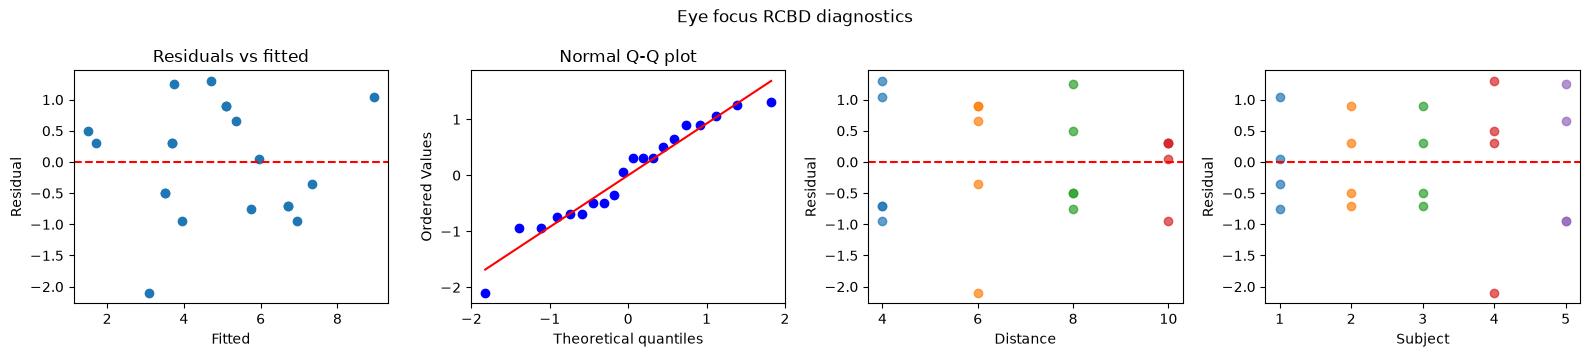

Shapiro-Wilk: W = 0.9498, p = 0.36343; do not reject normality (diagnostic)


,df,sum_sq,mean_sq,F,PR(>F)
C(Distance),3.0,32.950000,10.983333,8.041015,0.004078
C(Subject),4.0,36.300000,9.075000,6.643904,0.005688
q_nonadd,1.0,0.274947,0.274947,0.201292,0.662390
Residual,11.0,15.025053,1.365914,NaN,NaN


Nonadditivity: F(1, 11) = 0.2013, p = 0.66239; do not reject H0


In [39]:
residual_checks(focus_model, focus, ['Distance', 'Subject'], 'Eye focus RCBD diagnostics')
nonadditivity_report(focus, 'Time', 'Distance', 'Subject')

Shapiro–Wilk gives $W=0.950$, $p=0.363$, and Tukey’s nonadditivity test gives $F(1,11)=0.201$, $p=0.6624$. Neither test rejects its null hypothesis. The plots should be read with only one observation per distance–subject cell: they cannot rule out general interaction. The unusually short time for subject 4 at 6 ft merits attention, but there is no clear evidence here requiring rejection of the additive model. Randomization within subjects supports the independence assumption.

**Question 4.** Reanalyse the data ignoring the subjects (completely randomized design) and compute the relative efficiency of the RCBD. Was blocking on subjects worthwhile?

In [40]:
focus_crd = blocking_efficiency(focus_model, focus, 'Time', 'Distance', 'Subject')

CRD: H0 = equal treatment means; H1 = at least one differs.


,sum_sq,df,F,PR(>F)
C(Distance),32.95,3.0,3.405685,0.043367
Residual,51.60,16.0,NaN,NaN


C(Distance): F(3, 16) = 3.4057, p = 0.0433665; reject H0
Pooled error MS = 3.225
MSE RCBD = 1.27500, MSE CRD = 3.22500
Estimated CRD variance = 2.91711; relative efficiency R = 2.2161


Ignoring subjects raises $MS_E$ from 1.275 to 3.225. The distance test becomes $F(3,16)=3.406$, $p=0.04337$, still significant but much weaker. Corrected relative efficiency is $R=2.216$: roughly 2.2 times as many observations per distance would be needed in a comparable CRD. Blocking on subjects was useful.

**Question 5.** Assume that the subjects are a random sample of people. Estimate the block variance component $\hat\sigma^2_\beta = (MS_{Blocks} - MS_E)/a$.

In [41]:
ms_subject = focus_anova.loc['C(Subject)', 'sum_sq'] / focus_anova.loc['C(Subject)', 'df']
subject_variance = (ms_subject - focus_model.mse_resid) / focus['Distance'].nunique()
print(f'MS Subjects = {ms_subject:.3f}; estimated subject variance = {subject_variance:.3f}')

MS Subjects = 9.075; estimated subject variance = 1.950


The random-subject variance estimate is $(9.075-1.275)/4=1.950$ in squared time units. Between-person variability is substantial relative to residual variance 1.275, supporting use of subjects as blocks. This interpretation assumes subjects are independently sampled and subject effects enter additively.

### Problems 5.8, 5.23 and 5.36: breaking strength of a synthetic fibre

The factors that influence the breaking strength of a synthetic fibre are being studied. Four production machines and three
operators are chosen and a factorial experiment is run using fibre from the same production batch; two replicates.

In [42]:
fibre = pd.read_csv(URL + "Chapter5_Pr06.csv", sep=";")
display(fibre.pivot_table(index="Operator", columns="Machine", values="Strength", aggfunc=list))

Machine,1,2,3,4
Operator,,,,
1,"[109, 110]","[110, 115]","[108, 109]","[110, 108]"
2,"[110, 112]","[110, 111]","[111, 109]","[114, 112]"
3,"[116, 114]","[112, 115]","[114, 119]","[120, 117]"


**Question 1.** Draw an interaction plot, analyse the data and draw conclusions ($\alpha = 0.05$).

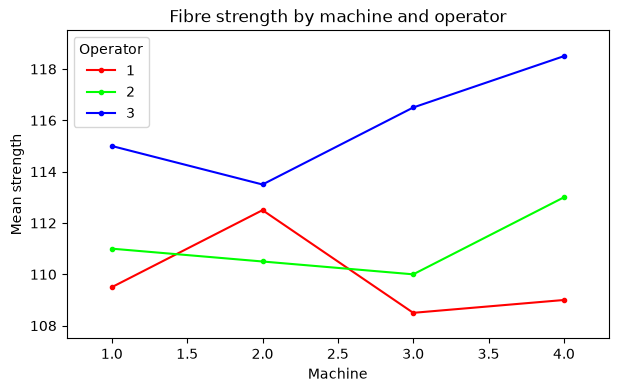

,sum_sq,df,F,PR(>F)
C(Machine),12.458333,3.0,1.095238,0.388753
C(Operator),160.333333,2.0,21.142857,0.000117
C(Machine):C(Operator),44.666667,6.0,1.963370,0.150681
Residual,45.500000,12.0,NaN,NaN


C(Machine): F(3, 12) = 1.0952, p = 0.388753; do not reject H0
C(Operator): F(2, 12) = 21.1429, p = 0.000116674; reject H0
C(Machine):C(Operator): F(6, 12) = 1.9634, p = 0.150681; do not reject H0
Pooled error MS = 3.79167


Operator
1    109.875
2    111.125
3    115.875
Name: Operator mean, dtype: float64

In [43]:
fig, ax = plt.subplots(figsize=(7, 4))
interaction_plot(fibre['Machine'], fibre['Operator'], fibre['Strength'], ax=ax)
ax.set(title='Fibre strength by machine and operator', ylabel='Mean strength')
plt.show()
# H0: equal machine marginal means; equal operator marginal means;
# and zero machine-by-operator interaction, respectively. Each H1 negates its H0.
fibre_model = smf.ols('Strength ~ C(Machine)*C(Operator)', data=fibre).fit()
fibre_anova = report_anova(fibre_model)
display(fibre.groupby('Operator')['Strength'].mean().rename('Operator mean'))

Operator has a significant effect, $F(2,12)=21.143$, $p=0.000117$. Machine ($F=1.095$, $p=0.3888$) and interaction ($F=1.963$, $p=0.1507$) are not significant. Operator 3 has the highest observed marginal mean, but this omnibus analysis alone does not identify all significant operator pairs. Conclusions concern the chosen machines and operators, treated as fixed factors.

**Question 2.** Prepare appropriate residual plots and comment on the model's adequacy.

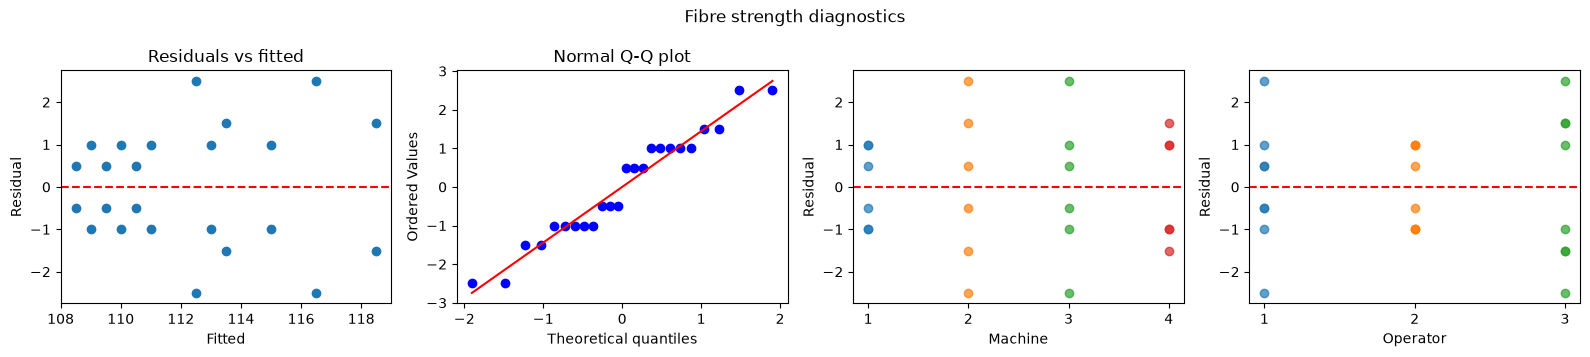

Shapiro-Wilk: W = 0.9493, p = 0.26107; do not reject normality (diagnostic)


In [44]:
residual_checks(fibre_model, fibre, ['Machine', 'Operator'], 'Fibre strength diagnostics')

Shapiro–Wilk gives $W=0.949$, $p=0.261$, with no strong normality warning. The spread is smaller for machine 1 and operator 2, but there is no consistent funnel across fitted values. With only two replicates per cell, individual cell variances are very uncertain. Residuals within a cell occur in opposite pairs, so pooled residual normality tests are only diagnostic. Independence requires randomized runs. The model supports an operator effect, with limited power to detect interaction.

**Question 3.** (Problems 5.23 and 5.36) Analyse the data assuming that the two replicates are blocks (the first observation in each cell
comes from the first replicate). Estimate the variance component for blocks, $\hat\sigma^2_{Block} = (MS_{Blocks} - MS_E)/(ab)$.
Does blocking change the conclusions?

In [45]:
fibre['Block'] = fibre.groupby(['Machine', 'Operator']).cumcount() + 1
# Same factorial hypotheses; additional H0: no replicate-block effect.
fibre_blocked = smf.ols('Strength ~ C(Machine)*C(Operator) + C(Block)', data=fibre).fit()
fibre_blocked_anova = report_anova(fibre_blocked)
fibre_block_variance = block_variance(fibre_blocked, cells_per_block=12)

,sum_sq,df,F,PR(>F)
C(Machine),12.458333,3.0,1.051135,0.408659
C(Operator),160.333333,2.0,20.291467,0.000204
C(Block),2.041667,1.0,0.516779,0.487209
C(Machine):C(Operator),44.666667,6.0,1.884308,0.171630
Residual,43.458333,11.0,NaN,NaN


C(Machine): F(3, 11) = 1.0511, p = 0.408659; do not reject H0
C(Operator): F(2, 11) = 20.2915, p = 0.000203646; reject H0
C(Block): F(1, 11) = 0.5168, p = 0.487209; do not reject H0
C(Machine):C(Operator): F(6, 11) = 1.8843, p = 0.17163; do not reject H0
Pooled error MS = 3.95076
MS Block = 2.04167; raw block variance estimate = -0.15909
Nonnegative variance estimate = 0.00000


The block effect is not significant, $F(1,11)=0.517$, $p=0.4872$. The raw method-of-moments variance estimate is −0.1591; a variance cannot be negative, so use 0 as the constrained estimate. Blocking increases $MS_E$ slightly (3.792 to 3.951) after losing a degree of freedom and shows no benefit. Operator remains significant ($p=0.000204$), while machine and interaction remain nonsignificant. Additive blocks are assumed.

### Problem 5.18: strength of paper (three factors)

The percentage of hardwood concentration in raw pulp (2, 4, 8 %), the vat pressure (400, 500, 650) and the cooking time of the
pulp (3.0, 4.0 hours) are being investigated for their effects on the strength of paper. A factorial experiment with two
replicates is conducted.

In [46]:
paper = pd.read_csv(URL + "Chapter5_Pr16.csv", sep=";")
display(paper.pivot_table(index=["Cooking_Time", "Hardwood"], columns="Pressure", values="Strength", aggfunc=list))

Pressure                          400             500             650
Cooking_Time Hardwood                                                
3            2         [196.6, 196.0]  [197.7, 196.0]  [199.8, 199.4]
             4         [198.5, 197.2]  [196.0, 196.9]  [198.4, 197.6]
             8         [197.5, 196.6]  [195.6, 196.2]  [197.4, 198.1]
4            2         [198.4, 198.6]  [199.6, 200.4]  [200.6, 200.9]
             4         [197.5, 198.1]  [198.7, 198.0]  [199.6, 199.0]
             8         [197.6, 198.4]  [197.0, 197.8]  [198.5, 199.8]

**Question 1.** Analyse the data and draw conclusions ($\alpha = 0.05$). Use plots of the main effects and of the important interactions.

,sum_sq,df,F,PR(>F)
C(Hardwood),7.763889,2.0,10.619301,8.995614e-04
C(Pressure),19.373889,2.0,26.499240,4.327241e-06
C(Cooking_Time),20.250000,1.0,55.395137,6.745340e-07
C(Hardwood):C(Pressure),6.091111,4.0,4.165653,1.462624e-02
C(Hardwood):C(Cooking_Time),2.081667,2.0,2.847264,8.425969e-02
C(Pressure):C(Cooking_Time),2.195000,2.0,3.002280,7.495643e-02
C(Hardwood):C(Pressure):C(Cooking_Time),1.973333,4.0,1.349544,2.903053e-01
Residual,6.580000,18.0,NaN,NaN


C(Hardwood): F(2, 18) = 10.6193, p = 0.000899561; reject H0
C(Pressure): F(2, 18) = 26.4992, p = 4.32724e-06; reject H0
C(Cooking_Time): F(1, 18) = 55.3951, p = 6.74534e-07; reject H0
C(Hardwood):C(Pressure): F(4, 18) = 4.1657, p = 0.0146262; reject H0
C(Hardwood):C(Cooking_Time): F(2, 18) = 2.8473, p = 0.0842597; do not reject H0
C(Pressure):C(Cooking_Time): F(2, 18) = 3.0023, p = 0.0749564; do not reject H0
C(Hardwood):C(Pressure):C(Cooking_Time): F(4, 18) = 1.3495, p = 0.290305; do not reject H0
Pooled error MS = 0.365556


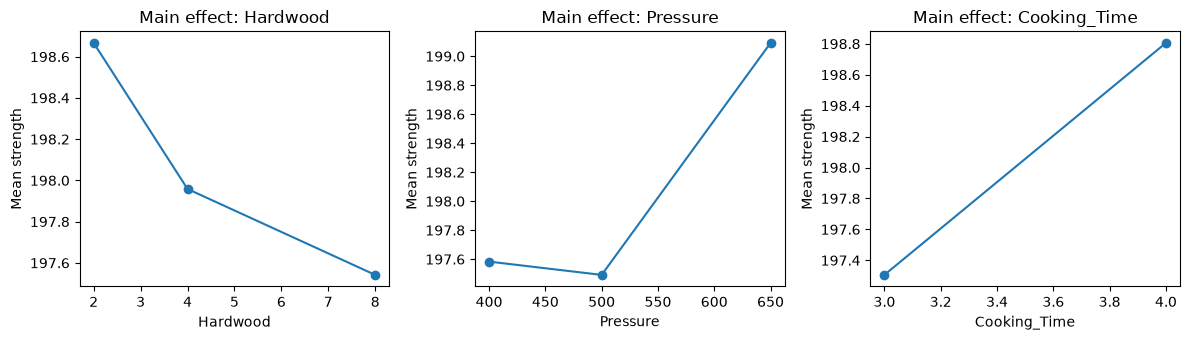

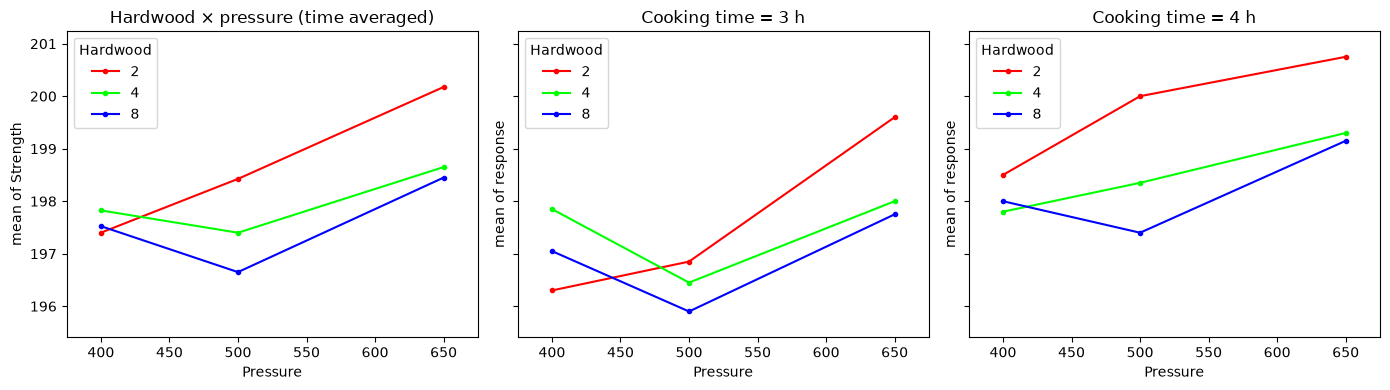

In [47]:
# Main-effect H0: equal marginal means; each interaction H0: all corresponding
# interaction coefficients are zero. H1: at least one relevant effect is nonzero.
paper_model = smf.ols('Strength ~ C(Hardwood)*C(Pressure)*C(Cooking_Time)', data=paper).fit()
paper_anova = report_anova(paper_model)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, factor in zip(axes, ['Hardwood', 'Pressure', 'Cooking_Time']):
    means = paper.groupby(factor)['Strength'].mean()
    ax.plot(means.index, means, marker='o')
    ax.set(xlabel=factor, ylabel='Mean strength', title=f'Main effect: {factor}')
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
interaction_plot(paper['Pressure'], paper['Hardwood'], paper['Strength'], ax=axes[0])
axes[0].set_title('Hardwood × pressure (time averaged)')
for ax, (time, group) in zip(axes[1:], paper.groupby('Cooking_Time')):
    interaction_plot(group['Pressure'].to_numpy(), group['Hardwood'].to_numpy(),
                     group['Strength'].to_numpy(), ax=ax, xlabel='Pressure', legendtitle='Hardwood')
    ax.set_title(f'Cooking time = {time} h')
plt.tight_layout()
plt.show()

Hardwood ($p=0.000900$), pressure ($p=4.33\times10^{-6}$) and cooking time ($p=6.75\times10^{-7}$) all have significant main effects. Hardwood × pressure is significant ($p=0.0146$), so hardwood choices should be considered jointly with pressure. Hardwood × time ($p=0.0843$), pressure × time ($p=0.0750$), and the three-way interaction ($p=0.2903$) are not significant at 5%. Retain the full model here to use pure replicated error ($MS_E=0.36556$, 18 df), without selecting the error term based on significance.

**Question 2.** Prepare appropriate residual plots and comment on the model's adequacy.

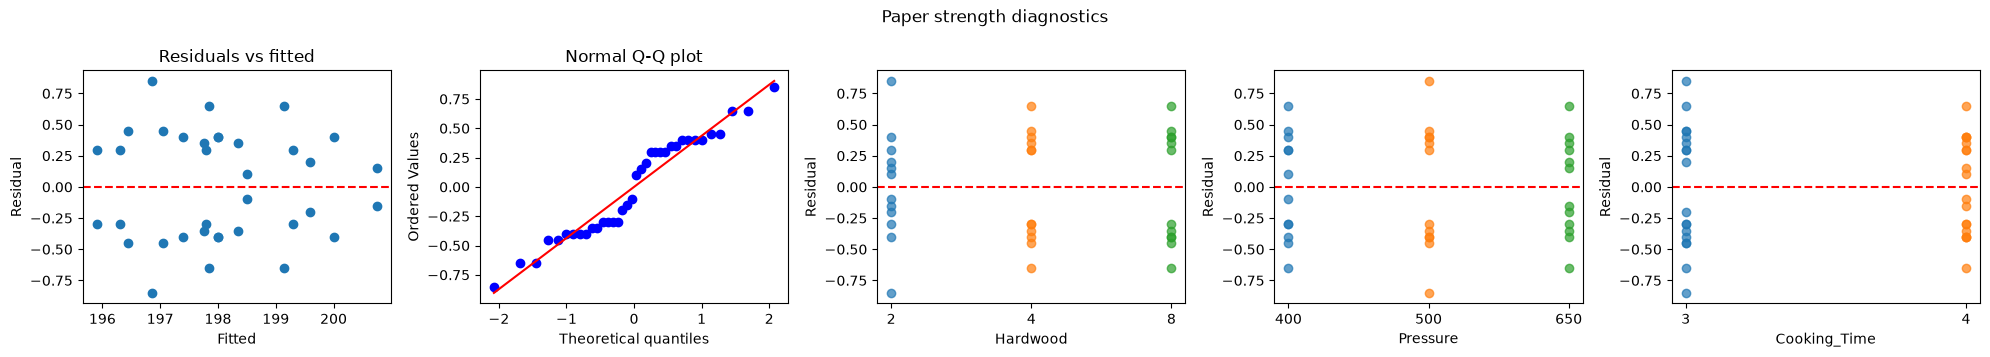

Shapiro-Wilk: W = 0.9390, p = 0.04717; reject normality at 0.05 (diagnostic)


In [48]:
residual_checks(paper_model, paper, ['Hardwood', 'Pressure', 'Cooking_Time'], 'Paper strength diagnostics')

Shapiro–Wilk gives $W=0.939$, $p=0.0472$, a borderline normality warning. With two replicates per cell, residuals come in opposite pairs and some replicate differences dominate the spread; the Q-Q plot has a central gap and plateaus, and hardwood 2 shows the largest residual range. Two replicates are insufficient for a reliable cellwise variance check. The ANOVA is useful but should be treated cautiously, especially the weaker interaction result; additional randomized replicates would help assess robustness.

**Question 3.** Under what set of conditions would you operate this process? Why?

In [49]:
paper_cell_means = paper.groupby(['Hardwood', 'Pressure', 'Cooking_Time'])['Strength'].mean()
display(paper_cell_means.sort_values(ascending=False).rename('Mean strength'))
best_paper = paper_cell_means.idxmax()
print(f'Highest observed mean: hardwood={best_paper[0]}%, pressure={best_paper[1]}, '
      f'cooking time={best_paper[2]} h; strength={paper_cell_means.max():.2f}')

Hardwood  Pressure  Cooking_Time
2         650       4               200.75
          500       4               200.00
          650       3               199.60
4         650       4               199.30
8         650       4               199.15
2         400       4               198.50
4         500       4               198.35
          650       3               198.00
8         400       4               198.00
4         400       3               197.85
                    4               197.80
8         650       3               197.75
          500       4               197.40
          400       3               197.05
2         500       3               196.85
4         500       3               196.45
2         400       3               196.30
8         500       3               195.90
Name: Mean strength, dtype: float64

Highest observed mean: hardwood=2%, pressure=650, cooking time=4 h; strength=200.75


If the objective is maximum paper strength, choose 2% hardwood, pressure 650, and cooking time 4 h as the candidate operating condition. It has the highest observed cell mean, 200.75, and respects the hardwood–pressure interaction. This is the best tested sample mean, not proof of a unique population optimum; confirm it with further runs and consider cost before committing to the longer cooking time or higher pressure.

### Problem 5.20: number of replicates (data of Problem 5.3)

The yield of a chemical process is studied at three pressures (200, 215, 230 psig) and three temperatures (150, 160, 170 $^\circ$C),
with two replicates (Problem 5.3).

In [50]:
yield_ = pd.read_csv(URL + "Chapter5_Pr01.csv", sep=";")
display(yield_.pivot_table(index="Temperature", columns="Pressure", values="Yield", aggfunc=list))

Pressure,200,215,230
Temperature,,,
150,"[90.4, 90.2]","[90.7, 90.6]","[90.2, 90.4]"
160,"[90.1, 90.3]","[90.5, 90.6]","[89.9, 90.1]"
170,"[90.5, 90.7]","[90.8, 90.9]","[90.1, 90.4]"


**Question 1.** (Problem 5.3) Analyse the data and draw conclusions ($\alpha = 0.05$).

,sum_sq,df,F,PR(>F)
C(Pressure),0.767778,2.0,21.59375,0.000367
C(Temperature),0.301111,2.0,8.46875,0.008539
C(Pressure):C(Temperature),0.068889,4.0,0.96875,0.470006
Residual,0.160000,9.0,NaN,NaN


C(Pressure): F(2, 9) = 21.5938, p = 0.000367318; reject H0
C(Temperature): F(2, 9) = 8.4688, p = 0.00853915; reject H0
C(Pressure):C(Temperature): F(4, 9) = 0.9688, p = 0.470006; do not reject H0
Pooled error MS = 0.0177778


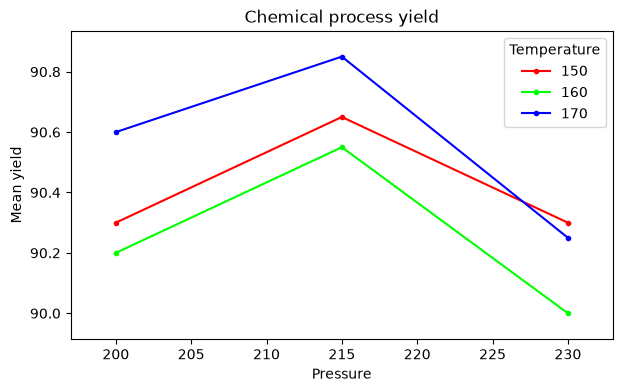

Pressure
200    90.366667
215    90.683333
230    90.183333
Name: Mean yield by pressure, dtype: float64

Temperature
150    90.416667
160    90.250000
170    90.566667
Name: Mean yield by temperature, dtype: float64

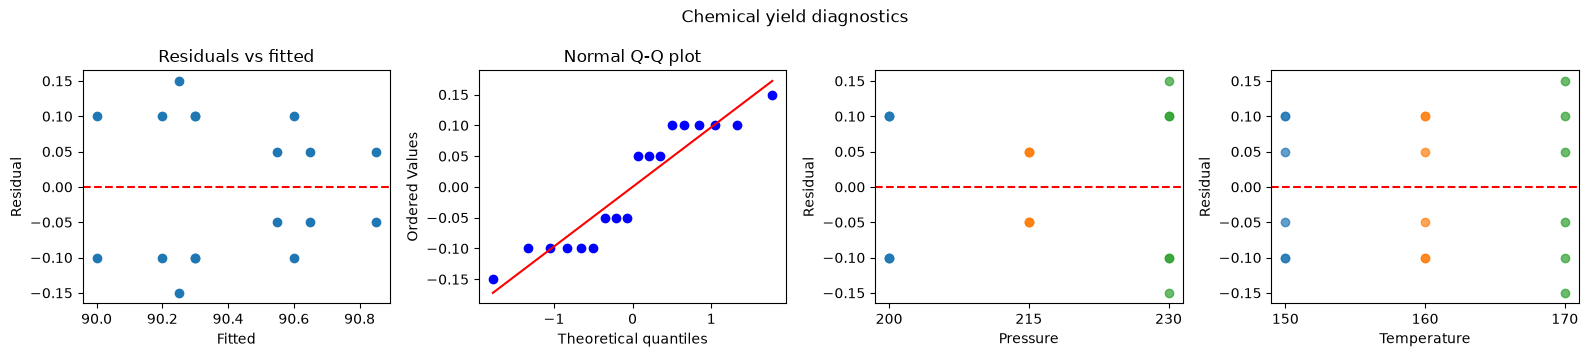

Shapiro-Wilk: W = 0.8737, p = 0.02046; reject normality at 0.05 (diagnostic)


In [51]:
# H0: equal pressure marginal means; equal temperature marginal means;
# zero pressure-by-temperature interaction. Each H1 negates the corresponding H0.
yield_model = smf.ols('Yield ~ C(Pressure)*C(Temperature)', data=yield_).fit()
yield_anova = report_anova(yield_model)
fig, ax = plt.subplots(figsize=(7, 4))
interaction_plot(yield_['Pressure'], yield_['Temperature'], yield_['Yield'], ax=ax)
ax.set(title='Chemical process yield', ylabel='Mean yield')
plt.show()
display(yield_.groupby('Pressure')['Yield'].mean().rename('Mean yield by pressure'))
display(yield_.groupby('Temperature')['Yield'].mean().rename('Mean yield by temperature'))
residual_checks(yield_model, yield_, ['Pressure', 'Temperature'], 'Chemical yield diagnostics')

Pressure ($F(2,9)=21.594$, $p=0.000367$) and temperature ($F(2,9)=8.469$, $p=0.00854$) affect yield. Interaction is not significant ($F(4,9)=0.969$, $p=0.4700$). The largest observed cell mean is 90.85 at pressure 215 psig and temperature 170°C. Shapiro–Wilk flags normality ($W=0.874$, $p=0.0205$); paired residuals from only two rounded observations per cell limit this diagnostic, but the warning should not be ignored. Residuals have a stepped Q-Q pattern and much smaller spread at pressure 215, so constant variance also deserves scrutiny. Treat model-based tests and power calculations as conditional on the common-variance normal-error approximation; independent randomized runs are assumed.

**Question 2.** (Problem 5.20) We wish to reject the null hypothesis with a high probability if the difference in the true mean
yield at any two pressures is as great as 0.5. If a reasonable prior estimate of the standard deviation of yield is 0.1,
how many replicates should be run? Compute the power for $n = 2, 3, 4$ with `anova_power()`.

In [52]:
# We interpret "high probability" as power >= 0.90, with alpha = 0.05.
# a = 3 pressures, b = 3 temperatures; n is replicates PER pressure-temperature cell.
# Least favourable pressure means with range D: (-D/2, 0, D/2) around their mean.
# lambda = b*n*D**2/(2*sigma**2), df1 = a-1, df2 = a*b*(n-1).
def pressure_power(D, sigma, n):
    a, b = 3, 3
    lam = b * n * D**2 / (2 * sigma**2)
    return anova_power(lam, a - 1, a*b*(n - 1), alpha=0.05)

def power_summary(D, sigma, target=0.90):
    rows = [{'n per cell': n, 'total runs': 9*n, 'power': pressure_power(D, sigma, n)}
            for n in [2, 3, 4]]
    display(pd.DataFrame(rows))
    n_needed = next(n for n in range(2, 1000) if pressure_power(D, sigma, n) >= target)
    print(f'D = {D:.3f}, sigma = {sigma:.5f}; minimum n >= 2 for power {target:.2f}: '
          f'{n_needed} per cell ({9*n_needed} runs), power = {pressure_power(D, sigma, n_needed):.6f}')
    return n_needed

n_prior = power_summary(D=0.5, sigma=0.1)

,n per cell,total runs,power
0,2,18,0.999999
1,3,27,1.000000
2,4,36,1.000000


D = 0.500, sigma = 0.10000; minimum n >= 2 for power 0.90: 2 per cell (18 runs), power = 0.999999


The pressure F test is an omnibus test, not a test of a single selected pair. For the least favourable configuration of three pressure means with range 0.5, two replicates per cell already exceed the chosen 90% power target (18 total runs). We restrict to $n\ge2$ because the full interaction model needs replication to estimate error. This calculation assumes the stated $\sigma=0.1$ and the same balanced factorial model.

**Question 3.** Repeat Question 2 with $\sigma$ estimated from the data of Problem 5.3 ($\hat\sigma = \sqrt{MS_E}$) and with a difference of 0.25. How sensitive is the required $n$ to these inputs?

In [53]:
sigma_yield = np.sqrt(yield_model.mse_resid)
n_estimated = power_summary(D=0.25, sigma=sigma_yield)
# Separate sensitivity to the smaller difference from sensitivity to the variance estimate.
sensitivity = []
for D, sigma, label in [(0.5, 0.1, 'Original assumptions'),
                        (0.25, 0.1, 'Smaller difference only'),
                        (0.5, sigma_yield, 'Estimated sigma only'),
                        (0.25, sigma_yield, 'Both changes')]:
    needed = next(n for n in range(2, 1000) if pressure_power(D, sigma, n) >= 0.90)
    sensitivity.append({'scenario': label, 'D': D, 'sigma': sigma,
                        'n per cell for 90% power': needed,
                        'power at n=2': pressure_power(D, sigma, 2)})
display(pd.DataFrame(sensitivity))

,n per cell,total runs,power
0,2,18,0.684922
1,3,27,0.914541
2,4,36,0.979431


D = 0.250, sigma = 0.13333; minimum n >= 2 for power 0.90: 3 per cell (27 runs), power = 0.914541


,scenario,D,sigma,n per cell for 90% power,power at n=2
0,Original assumptions,0.50,0.100000,2,0.999999
1,Smaller difference only,0.25,0.100000,2,0.909861
2,Estimated sigma only,0.50,0.133333,2,0.998849
3,Both changes,0.25,0.133333,3,0.684922


The estimated standard deviation is $\sqrt{0.0177778}=0.13333$. Halving the detectable difference reduces noncentrality by a factor of four, and replacing 0.1 by 0.13333 reduces it further: together the noncentrality is only 0.140625 times its original value at a fixed $n$. The powers for 2, 3 and 4 replicates per cell are 0.6849, 0.9145 and 0.9794. Thus 3 replicates per cell (27 total runs) are needed for the chosen 90% target, compared with 2 under the original assumptions. This is prospective planning for detecting a specified effect, not “observed power”; the variance estimate is uncertain (9 error df), so the result should guide planning rather than guarantee achieved power.